In [ ]:
import string
import warnings
import scipy
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import Normalize
from matplotlib.cm import viridis, Spectral_r

# ----------------------------
# Illustrator-friendly settings
# ----------------------------
# Illustrator-friendly settings with Times New Roman
import matplotlib as mpl
mpl.rcParams['font.family'] = ['Times New Roman']  # Times New Roman
mpl.rcParams['svg.fonttype'] = 'none'        # Keeps text editable in Illustrator
mpl.rcParams['pdf.fonttype'] = 42            # Keeps text editable in PDF if you export to PDF

warnings.filterwarnings("ignore", message=".*use_inf_as_na option is deprecated.*") # Ignore pandas warning about deprecated option

# Function to read the time series data in each cell
def convert_to_list(string):
    # Converts a space-separated string (e.g., "[1.0 2.0 3.0]") to a list of floats
    values = [float(num) for num in string[1:-1].replace(',', '').split()]
    return [v if np.isfinite(v) else np.nan for v in values]

## Data processing from raw DLC bodyparts coordinates to COM coordinates and then to take-off speed, take-off angle and body angle

In [ ]:
import scipy
import pandas as pd
import numpy as np

def read_filter_df(filename):
    """
    Read data from a CSV file, apply a low-pass Butterworth filter, and return filtered data as integers.
    
    Parameters:
        filename (str): The name of the CSV file containing the data.
        
    Returns:
        pd.DataFrame: A DataFrame containing the filtered data with the same column structure as the input, with integer values.
    """
    df = pd.read_csv(filename)  # Read the CSV file into a DataFrame
    b, a = scipy.signal.butter(3, 75, 'low', fs=2000)  # Design Butterworth low-pass filter
    
    # Apply the filter to each column, convert to integers, and return the filtered DataFrame
    return df.apply(lambda col: scipy.signal.filtfilt(b, a, col))

def calc(metadata_file):
    meta_df = pd.read_csv(metadata_file)

    # Add new columns
    extra_cols = [
        'TakeOffSpeed', 'TakeOffAngle', 'TargetDistance', 'TargetAngle',
        'Speed_TimeSeries', 'Angle_TimeSeries',
        'BodyAngle_TimeSeries', 'COM_x', 'COM_y'
    ]
    for col in extra_cols:
        meta_df[col] = None

    for i, row in meta_df.iterrows():
        df = read_filter_df("CSV files with position coordinates/" + row['filename'])

        # COM
        # Calculate the center of mass (COM) coordinates of the insect at each time step
        x_com = (
            ((df['Head_x'] + df['ProThorax_x']) / 2) * row['Head_Mass'] +
            ((df['ProThorax_x'] + df['MesoThorax_x']) / 2) * row['ProThorax_Mass'] +
            ((df['MesoThorax_x'] + df['MetaThorax_x']) / 2) * row['MesoThorax_Mass'] +
            ((df['MetaThorax_x'] + df['Abdomen_x']) / 2) * row['MetaThorax_Mass'] +
            ((df['Abdomen_x'] + df['Abdomen_Mid_x'] + df['Abdomen_Tip_x']) / 3) * row['Abdomen_Mass'] +
            ((df['FL_Tibia_x'] + df['FL_Femur_x']) / 2) * (row['FL_Tib+Tar_Mass'] * 2) +
            ((df['FL_Femur_x'] + df['FL_Trochanter_x']) / 2) * (row['FL_Fem_Mass'] * 2) +
            ((df['FL_Trochanter_x'] + df['FL_Coxa_x']) / 2) * (row['FL_Cox+Tro_Mass'] * 2) +
            ((df['ML_Tarsi_x'] + df['ML_Femur_x']) / 2) * (row['ML_Tib+Tar_Mass'] * 2) +
            ((df['ML_Femur_x'] + df['ML_Trochanter_x']) / 2) * (row['ML_Fem_Mass'] * 2) +
            ((df['ML_Trochanter_x'] + df['ML_Coxa_x']) / 2) * (row['ML_Tro_Mass'] * 2) +
            ((df['HL_Tarsi_x'] + df['HL_Femur_x']) / 2) * (row['HL_Tib+Tar_Mass'] * 2) +
            ((df['HL_Femur_x'] + df['HL_Trochanter_x']) / 2) * (row['HL_Fem_Mass'] * 2) +
            ((df['HL_Trochanter_x'] + df['HL_Coxa_x']) / 2) * (row['HL_Tro_Mass'] * 2)
        ) / row['mass(g)']


        y_com = (
            ((df['Head_y'] + df['ProThorax_y']) / 2) * row['Head_Mass'] +
            ((df['ProThorax_y'] + df['MesoThorax_y']) / 2) * row['ProThorax_Mass'] +
            ((df['MesoThorax_y'] + df['MetaThorax_y']) / 2) * row['MesoThorax_Mass'] +
            ((df['MetaThorax_y'] + df['Abdomen_y']) / 2) * row['MetaThorax_Mass'] +
            ((df['Abdomen_y'] + df['Abdomen_Mid_y'] + df['Abdomen_Tip_y']) / 3) * row['Abdomen_Mass'] +
            ((df['FL_Tibia_y'] + df['FL_Femur_y']) / 2) * (row['FL_Tib+Tar_Mass'] * 2) +
            ((df['FL_Femur_y'] + df['FL_Trochanter_y']) / 2) * (row['FL_Fem_Mass'] * 2) +
            ((df['FL_Trochanter_y'] + df['FL_Coxa_y']) / 2) * (row['FL_Cox+Tro_Mass'] * 2) +
            ((df['ML_Tarsi_y'] + df['ML_Femur_y']) / 2) * (row['ML_Tib+Tar_Mass'] * 2) +
            ((df['ML_Femur_y'] + df['ML_Trochanter_y']) / 2) * (row['ML_Fem_Mass'] * 2) +
            ((df['ML_Trochanter_y'] + df['ML_Coxa_y']) / 2) * (row['ML_Tro_Mass'] * 2) +
            ((df['HL_Tarsi_y'] + df['HL_Femur_y']) / 2) * (row['HL_Tib+Tar_Mass'] * 2) +
            ((df['HL_Femur_y'] + df['HL_Trochanter_y']) / 2) * (row['HL_Fem_Mass'] * 2) +
            ((df['HL_Trochanter_y'] + df['HL_Coxa_y']) / 2) * (row['HL_Tro_Mass'] * 2)
        ) / row['mass(g)']
        
        # Frame-to-frame displacement
        dx = np.diff(x_com, prepend=x_com[0])
        dy = np.diff(y_com, prepend=y_com[0])

        # Speed (m/s)
        speed = np.hypot(dx, dy) * row['pixelsize(m)'] * row['framerate(Hz)']

        # Angle (direction of motion, degrees; horizontal reference)
        angle = np.degrees(np.arctan2(dx, dy)) - 90

        # Body angle    
        body_angle = np.degrees(np.arctan2(df['MesoThorax_x'] - df['ProThorax_x'], df['MesoThorax_y'] - df['ProThorax_y'])) + 90

        # Takeoff indices
        takeoff_idx = int(row['takeofftime(ms)'] * 2)

        # Takeoff speed and angle
        u = speed[takeoff_idx]
        theta = float(angle[takeoff_idx])

        # Target geometry
        xt = row['TargetPlatform_x'] - df['Head_x'][0] # x distance to target from head at frame 0
        yt = row['TargetPlatform_y'] - df['Head_y'][0] # y distance to target from head at frame 0
        td = float(np.hypot(xt, yt) * row['pixelsize(m)'])
        phi = np.degrees(np.arctan2(xt, yt)) - 90
        xt_com = (row['TargetPlatform_x'] - x_com[takeoff_idx]) # x distance to target from COM at takeoff
        yt_com = (row['TargetPlatform_y'] - y_com[takeoff_idx]) # y distance to target from COM at takeoff
        td_com = float(np.hypot(xt_com, yt_com) * row['pixelsize(m)'])
        phi_com = np.degrees(np.arctan2(xt_com, yt_com)) - 90
                                                
        # Store results
        meta_df.at[i, 'TakeOffSpeed'] = round(u, 3)
        meta_df.at[i, 'TakeOffAngle'] = round(theta, 3)
        meta_df.at[i, 'TargetDistance'] = round(td, 3)
        meta_df.at[i, 'TargetAngle'] = round(phi, 3)
        meta_df.at[i, 'TargetDistance_COM'] = round(td_com, 3)
        meta_df.at[i, 'TargetAngle_COM'] = round(phi_com, 3)
        meta_df.at[i, 'Speed_TimeSeries'] = [float(round(v, 3)) for v in speed]
        meta_df.at[i, 'Angle_TimeSeries'] = [float(round(v, 0)) for v in angle]
        meta_df.at[i, 'BodyAngle_TimeSeries'] = [float(round(v, 3)) for v in body_angle]
        meta_df.at[i, 'COM_x'] = [float(round(v, 3)) for v in x_com]
        meta_df.at[i, 'COM_y'] = [float(round(v, 3)) for v in y_com]
    meta_df.to_csv(metadata_file, index=False)

# Remove the comment below to run the function
#calc('JumpKinematics.csv')

# Data processing from raw DLC Head coordinates and to peering amplitude and frequency

In [ ]:
import pandas as pd
import numpy as np
import scipy.signal


def read_filter_df_peering(filename, fs=50):
    """
    Read data from CSV and apply a low-pass Butterworth filter.
    Returns filtered data as integers.
    """
    df = pd.read_csv(filename)
    b, a = scipy.signal.butter(3, fs/2.1, 'low', fs=fs)
    return df.apply(lambda col: scipy.signal.filtfilt(b, a, col).astype(int), axis=0)


def compute_td_freq_amp(filename, start_ms, stop_ms, target_y, pixelsize, framerate):
    """
    Computes:
        - Target distance from mean position of the Head
        - Oscillation frequency of Head_x (FFT peak)
        - Oscillation amplitude of Head_x (FFT peak amplitude, mm)

    All computed in the SAME start–stop window, with FFT-based amplitude.
    """

    # Load + filter
    data = read_filter_df_peering(filename, fs=framerate)

    # Convert ms → frames
    start_frame = int(start_ms / 1000 * framerate)
    stop_frame  = int(stop_ms  / 1000 * framerate)

    # Extract window
    seg_y = data["Head_y"].iloc[start_frame : stop_frame + 1]
    seg_x = data["Head_x"].iloc[start_frame : stop_frame + 1]

    # Calculating taregt distance in mm
    mean_y = seg_y.mean()
    td_pixels = int(mean_y) - int(target_y)
    td_mm = td_pixels * pixelsize * 1000   # converting m→mm

    # Calcualting peak frequency and amplitude of Head_x uisng FFT
    x_centered = seg_x - seg_x.iloc[-1] # Center around last point to remove DC offset
    n = len(x_centered)
    freqs = np.fft.rfftfreq(n, d=1/framerate)
    fft_vals = np.abs(np.fft.rfft(x_centered)) * 2 / n  # Scaled for true amplitude

    # Peak frequency (Hz) and amplitude (mm)
    if len(fft_vals) < 2:
        freq_hz = np.nan
        amp_mm = np.nan
    else:
        peak_index = np.argmax(fft_vals[1:]) + 1  # skip DC
        freq_hz = freqs[peak_index]
        amp_mm = fft_vals[peak_index] * pixelsize * 1000 # converting m→mm

    return float(f"{td_mm:.2f}"), float(f"{freq_hz:.2f}"), float(f"{amp_mm:.2f}") # Returns target distance (mm), peak frequency (Hz) and peak amplitude (mm)

# Calculate peering frequency and amplitude for each trial in the metadata CSV
df = pd.read_csv("PeeringKinematics.csv")

# Convert required columns to numeric
num_cols = ["start(ms)", "stop(ms)", "Target_y", "pixelsize(m)", "framerate(Hz)"]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(subset=["start(ms)", "stop(ms)", "Target_y"])

# Run unified computation
df[["TargetDistance(mm)", "Frequency(Hz)", "Amplitude(mm)"]] = df.apply(
    lambda row: pd.Series(
        compute_td_freq_amp("CSV files with position coordinates/" + row["filename"], row["start(ms)"], row["stop(ms)"], row["Target_y"], row["pixelsize(m)"], row["framerate(Hz)"])
    ), axis=1)

# Remove the comment below to run the function
#df.to_csv("PeeringKinematics.csv", index=False)

# Figures plots

## Fig 1

### Fig 1D

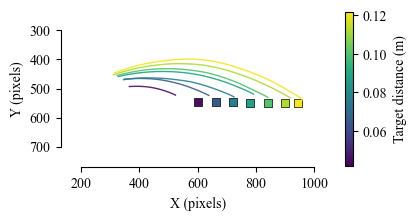

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import Normalize
from matplotlib.cm import viridis, ScalarMappable

# Load + filter data
df = pd.read_csv("JumpKinematics.csv").dropna()
df = df[(df["Experiment"] == "Distance") & (df["Individual ID"] == "M17")]

# Plot
fig, ax = plt.subplots(figsize=(4, 2))

norm = Normalize(vmin=df["TargetDistance"].min(),
                 vmax=df["TargetDistance"].max())

for i, (_, row) in enumerate(df.iterrows()):
    if (i - 4) % 5 != 0:   # keep only every 5th trial
        continue
    com_x = convert_to_list(row["COM_x"])
    com_y = convert_to_list(row["COM_y"])
    if np.all(np.isnan(com_x)) or np.all(np.isnan(com_y)):
        continue

    takeoff_idx   = int(row["takeofftime(ms)"] * 2)
    touchdown_idx = int(row["touchdown(ms)"] * 2)

    com_x = com_x[takeoff_idx:touchdown_idx + 1]
    com_y = com_y[takeoff_idx:touchdown_idx + 1]

    color = viridis(norm(row["TargetDistance"]))
    ax.plot(com_x, com_y, color=color, lw=1, alpha=0.9)
    ax.scatter(row["TargetPlatform_x"], row["TargetPlatform_y"],
               c=[color], marker="s", s=30,
               edgecolors="black", linewidths=0.5)

ax.set_xlabel("X (pixels)")
ax.set_ylabel("Y (pixels)")
ax.set_aspect("equal")
ax.set_xlim(200, 1000)
ax.set_ylim(700, 300)
sns.despine(ax=ax, top=True, right=True, left=False, bottom=False, offset=15, trim=False)

sm = ScalarMappable(norm=norm, cmap=viridis)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.1)
cbar.set_label("Target distance (m)")

#fig.savefig("Fig1D_COM_traces_Distance_M17.svg", format="svg")
plt.show()


### Fig 1E

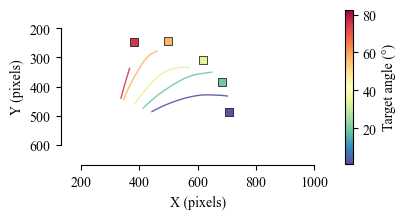

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import Normalize
from matplotlib.cm import Spectral_r, ScalarMappable

# Load + filter data
df = pd.read_csv("JumpKinematics.csv").dropna()
df = df[(df["Experiment"] == "Angle") & (df["Individual ID"] == "M37")]

# Plot
fig, ax = plt.subplots(figsize=(4, 2))

norm = Normalize(vmin=df["TargetAngle"].min(),
                 vmax=df["TargetAngle"].max())

for i, (_, row) in enumerate(df.iterrows()):
    if (i - 4) % 5 != 0:   # keep only every 5th trial
        continue
    com_x = convert_to_list(row["COM_x"])
    com_y = convert_to_list(row["COM_y"])
    if np.all(np.isnan(com_x)) or np.all(np.isnan(com_y)):
        continue

    takeoff_idx   = int(row["takeofftime(ms)"] * 2)
    touchdown_idx = int(row["touchdown(ms)"] * 2)

    com_x = com_x[takeoff_idx:touchdown_idx + 1]
    com_y = com_y[takeoff_idx:touchdown_idx + 1]

    color = Spectral_r(norm(row["TargetAngle"]))
    ax.plot(com_x, com_y, color=color, lw=1, alpha=0.9)
    ax.scatter(row["TargetPlatform_x"], row["TargetPlatform_y"],
               c=[color], marker="s", s=30,
               edgecolors="black", linewidths=0.5)

ax.set_xlabel("X (pixels)")
ax.set_ylabel("Y (pixels)")
ax.set_aspect("equal")
ax.set_xlim(200, 1000)
ax.set_ylim(600, 200)
sns.despine(ax=ax, top=True, right=True, left=False, bottom=False, offset=15, trim=False)

sm = ScalarMappable(norm=norm, cmap=Spectral_r)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.1)
cbar.set_label("Target angle (°)")

#fig.savefig("Fig1E_COM_traces_Angle_M37.svg", format="svg")
plt.show()


### Fig 1F

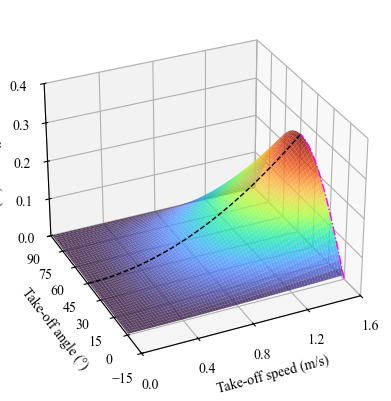

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

g, cutoff = 9.81, 1.6

def calculate_R(phi, theta, u):
    pr, tr = np.radians(phi), np.radians(theta)
    d = np.sin(2*tr - pr) - np.sin(pr)
    R = (u**2 * d) / (g * np.cos(pr)**2)
    R[(d == 0) | (R <= 0) | (R >= cutoff)] = np.nan
    return R

# Load + filter
df = pd.read_csv("JumpKinematics.csv")
df = df[df["Experiment"] == "Distance"]

theta = np.linspace(-15, 90, 120)
u = np.linspace(0, cutoff, 160)

xlim, ylim, zlim = (0, 1.6), (-15, 90), (0, 0.4)
phi_mean = 0

Tg, Ug = np.meshgrid(theta, u, indexing="ij")
R = calculate_R(phi_mean, Tg, Ug)

R[(Ug < xlim[0]) | (Ug > xlim[1]) |
(Tg < ylim[0]) | (Tg > ylim[1]) |
(R < zlim[0]) | (R > zlim[1])] = np.nan

fig = plt.figure(figsize=(8, 4))
ax = fig.add_subplot(111, projection="3d")

surf = ax.plot_surface(
    Ug, Tg, R,
    cmap="turbo",
    edgecolor="none",
    linewidth=0,
    antialiased=True,
    alpha=0.8,
    rcount=100, ccount=100
)

theta_opt = 45 + phi_mean / 2
u_line = np.linspace(0, cutoff, 300)
R_opt = calculate_R(phi_mean, np.full_like(u_line, theta_opt), u_line)
R_opt[(u_line < xlim[0]) | (u_line > xlim[1]) | (R_opt > zlim[1])] = np.nan

ax.plot(u_line, np.full_like(u_line, theta_opt), R_opt, "k--", lw=1, zorder=10)

theta_min, theta_max = phi_mean, 45 + 0.5 * phi_mean
u_diag = xlim[1]
theta_diag = np.linspace(theta_min, theta_max, 300)

R_diag = calculate_R(phi_mean, theta_diag, u_diag)
R_diag[(R_diag < zlim[0]) | (R_diag > zlim[1])] = np.nan

ax.plot(u_diag, theta_diag, R_diag, color="magenta", linestyle="-.", lw=1, zorder=10)

ax.set(xlabel="Take-off speed (m/s)",
    ylabel="Take-off angle (°)",
    zlabel="Target distance (m)",
    xlim=xlim, ylim=ylim, zlim=zlim)

ax.xaxis.set_major_locator(MultipleLocator(0.4))
ax.yaxis.set_major_locator(MultipleLocator(15))
ax.zaxis.set_major_locator(MultipleLocator(0.1))

ax.view_init(elev=30, azim=245)

plt.tight_layout()
#plt.savefig("Fig1F_Model_FixedPhi.svg")
plt.show()


### Fig 1G

C:\Users\Girish\AppData\Local\Temp\ipykernel_21872\3885356341.py:12: RuntimeWarning: invalid value encountered in sqrt
  u = np.sqrt((g * R * np.cos(phi_rad)**2) / denom)


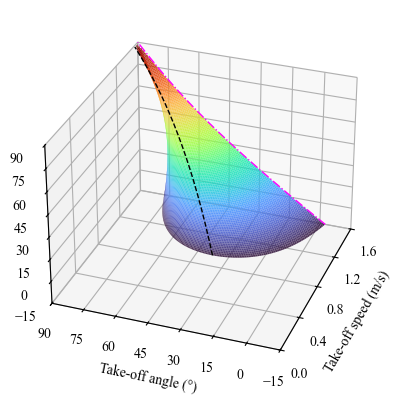

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

g, cutoff = 9.81, 1.6

def calculate_u(theta, R, phi, cutoff_u):
    theta_rad = np.radians(theta)
    phi_rad = np.radians(phi)
    denom = np.sin(2*theta_rad - phi_rad) - np.sin(phi_rad)
    denom = np.where(denom == 0, np.nan, denom)
    u = np.sqrt((g * R * np.cos(phi_rad)**2) / denom)
    return np.where((u >= cutoff_u) | (u < 0), np.nan, u)

# Axes ranges
theta = np.linspace(-15, 90, 1000)   # take-off angle
phi   = np.linspace(-15, 90, 1000)   # target angle
R_mean = 0.12                        # fixed distance

xlim, ylim, zlim = (0, 1.6), (-15, 90), (-15, 90)

Tg, Pg = np.meshgrid(theta, phi, indexing="ij")
Ug = calculate_u(Tg, R_mean, Pg, cutoff)

Ug[(Ug < xlim[0]) | (Ug > xlim[1])] = np.nan

fig = plt.figure(figsize=(8, 4))
ax = fig.add_subplot(111, projection="3d")

# Surface: speed as function of theta & phi
surf = ax.plot_surface(
    Ug, Tg, Pg,
    cmap="turbo",
    edgecolor="none",
    linewidth=0,
    antialiased=True,
    alpha=0.85,
    rcount=150, ccount=150
)

phi_line = np.linspace(-15, 90, 200)
theta_opt = 45 + phi_line / 2
u_opt = calculate_u(theta_opt, R_mean, phi_line, cutoff)

ax.plot(u_opt, theta_opt, phi_line, "k--", lw=1, zorder=10)

phi_bound = np.linspace(zlim[0], zlim[1], 400)
u_bound = np.full_like(phi_bound, cutoff)

phi_rad = np.radians(phi_bound)
arg = (g * R_mean * np.cos(phi_rad)**2) / cutoff**2 + np.sin(phi_rad)
arg = np.clip(arg, -1, 1)

theta_bound = 0.5 * (np.degrees(np.arcsin(arg)) + phi_bound)
theta_bound[(theta_bound < ylim[0]) | (theta_bound > ylim[1])] = np.nan

ax.plot(u_bound, theta_bound, phi_bound, color="magenta", linestyle="-.", lw=1, zorder=10)

ax.set(
    xlabel="Take-off speed (m/s)",
    ylabel="Take-off angle (°)",
    zlabel="Target angle (°)",
    xlim=xlim, ylim=ylim, zlim=zlim
)

ax.xaxis.set_major_locator(MultipleLocator(0.4))
ax.yaxis.set_major_locator(MultipleLocator(15))
ax.zaxis.set_major_locator(MultipleLocator(15))

ax.view_init(elev=30, azim=200)

plt.tight_layout()
#plt.savefig("Fig1G_Model_FixedR.svg")
plt.show()


## Fig 2

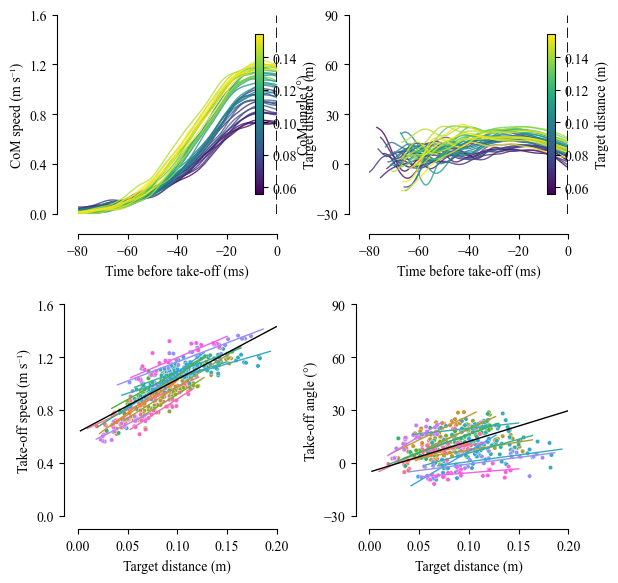

   Individual ID  body_length  body_mass  sample_size  slope  intercept  \
0            M12       27.156      0.129         40.0  3.478      0.627   
1            M13       43.654      0.625         20.0  5.201      0.505   
2            M14       36.805      0.406         31.0  5.543      0.501   
3            M15       61.452      1.711         40.0  4.781      0.499   
4            M16       43.660      0.686         25.0  4.717      0.448   
5            M17       31.421      0.161         35.0  4.201      0.670   
6            M18       36.578      0.292         35.0  4.899      0.574   
7            M19       55.089      0.782         35.0  2.784      0.813   
8            M20       47.299      0.476         35.0  2.393      0.807   
9            M21       64.000      1.297         23.0  2.173      0.825   
10           M22       59.120      1.539         27.0  5.484      0.539   
11           M23       70.850      0.885         25.0  2.886      0.876   
12           M24       16

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable, viridis
from matplotlib.ticker import MultipleLocator
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.stats import linregress
import statsmodels.formula.api as smf

# Load dataset
df = pd.read_csv('JumpKinematics.csv')
df_scatter = df[df["Experiment"] == "Distance"].dropna(subset=["TargetDistance", "TakeOffSpeed", "TakeOffAngle"])

# Helper: Convert stored list string → array
def convert_to_list(cell):
    return np.array(eval(cell))

# ----------------------------
# Time-series plotting function
# ----------------------------
def plot_ts(ax, df, col, cmap, ylims, ystep, xlabel="", ylabel=""):
    norm = Normalize(vmin=df['TargetDistance'].min(),
                     vmax=df['TargetDistance'].max())

    for _, row in df.iterrows():
        series = convert_to_list(row[col])
        takeoff_idx = int(row['takeofftime(ms)'] * 2)

        if col == "Angle_TimeSeries":
            speed = convert_to_list(row["Speed_TimeSeries"])
            speed_mask = speed >= 0.05
            series = np.where(speed_mask, series, np.nan)

        time = (np.arange(len(series)) - takeoff_idx) / 2

        ax.plot(time, series,
                color=cmap(norm(row['TargetDistance'])),
                linewidth=1, alpha=0.8)

    ax.axvline(0, color='k', linestyle='--', lw=2)
    ax.set_xlim([-80, 0])
    ax.set_ylim(ylims)
    ax.set_box_aspect(1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.yaxis.set_major_locator(MultipleLocator(ystep))
    sns.despine(ax=ax, offset=15)

    sm = ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    cax = inset_axes(ax, width="4%", height="80%",
                     loc='center right', borderpad=1)
    cbar = plt.colorbar(sm, cax=cax)
    cbar.set_label('Target distance (m)')

# Regression helper (Individual)
def reg(ax, x, y, c):
    if len(x) > 1:
        p = np.polyfit(x, y, 1)
        xr = x.max() - x.min()
        xx = np.linspace(x.min() - 0.1*xr, x.max() + 0.1*xr, 100)
        ax.plot(xx, np.polyval(p, xx), color=c, linewidth=1)

# Fit Mixed-Effects Models (Random Slope & Intercept)
# ----------------------------
# Speed vs Distance Mixed Model
md_speed = smf.mixedlm("TakeOffSpeed ~ TargetDistance", df_scatter, 
                       groups=df_scatter["Individual ID"], 
                       re_formula="~TargetDistance")
mdf_speed = md_speed.fit()

# Angle vs Distance Mixed Model
md_angle = smf.mixedlm("TakeOffAngle ~ TargetDistance", df_scatter, 
                       groups=df_scatter["Individual ID"], 
                       re_formula="~TargetDistance")
mdf_angle = md_angle.fit()

# Figure layout (2x2)
fig, axes = plt.subplots(2, 2, figsize=(6, 6))

ax_ts_speed  = axes[0, 0]
ax_ts_angle  = axes[0, 1]
ax_sc_speed  = axes[1, 0]
ax_sc_angle  = axes[1, 1]

# Top row — Time series (Individual M15)
df_m15 = df[df['Individual ID'] == 'M15']

plot_ts(ax_ts_speed, df_m15, 'Speed_TimeSeries', viridis,
        [0, 1.6], 0.4,
        xlabel='Time before take-off (ms)',
        ylabel='CoM speed (m s⁻¹)')

plot_ts(ax_ts_angle, df_m15, 'Angle_TimeSeries', viridis,
        [-30, 90], 30,
        xlabel='Time before take-off (ms)',
        ylabel='CoM angle (°)')

# Bottom row — Scatter + regression
ids = df_scatter["Individual ID"].unique()
palette = sns.color_palette("husl", len(ids))

# 1. Speed vs distance
sns.scatterplot(df_scatter, x="TargetDistance", y="TakeOffSpeed",
                hue="Individual ID", palette=palette,
                s=10, legend=False, ax=ax_sc_speed)

for c, i in zip(palette, ids):
    d = df_scatter[df_scatter["Individual ID"] == i]
    reg(ax_sc_speed, d["TargetDistance"], d["TakeOffSpeed"], c)

# Plot Population Mixed-Effects Fit Line (Black)
xr_speed = df_scatter["TargetDistance"].max() - df_scatter["TargetDistance"].min()
xx_speed = np.linspace(df_scatter["TargetDistance"].min() - 0.1*xr_speed, 
                       df_scatter["TargetDistance"].max() + 0.1*xr_speed, 100)
fixed_intercept_speed = mdf_speed.params["Intercept"]
fixed_slope_speed = mdf_speed.params["TargetDistance"]
ax_sc_speed.plot(xx_speed, fixed_intercept_speed + fixed_slope_speed * xx_speed, 
                 color='black', linewidth=1, label='Mixed Model Fit')

ax_sc_speed.set(xlim=(0, 0.2), ylim=(0, 1.6),
                xlabel="Target distance (m)",
                ylabel="Take-off speed (m s⁻¹)")
ax_sc_speed.xaxis.set_major_locator(MultipleLocator(0.05))
ax_sc_speed.yaxis.set_major_locator(MultipleLocator(0.4))
sns.despine(ax=ax_sc_speed, offset=10)

# 2. Angle vs distance
sns.scatterplot(df_scatter, x="TargetDistance", y="TakeOffAngle",
                hue="Individual ID", palette=palette,
                s=10, legend=False, ax=ax_sc_angle)

for c, i in zip(palette, ids):
    d = df_scatter[df_scatter["Individual ID"] == i]
    reg(ax_sc_angle, d["TargetDistance"], d["TakeOffAngle"], c)

# Plot Population Mixed-Effects Fit Line (Black)
xr_angle = df_scatter["TargetDistance"].max() - df_scatter["TargetDistance"].min()
xx_angle = np.linspace(df_scatter["TargetDistance"].min() - 0.1*xr_angle, 
                       df_scatter["TargetDistance"].max() + 0.1*xr_angle, 100)
fixed_intercept_angle = mdf_angle.params["Intercept"]
fixed_slope_angle = mdf_angle.params["TargetDistance"]
ax_sc_angle.plot(xx_angle, fixed_intercept_angle + fixed_slope_angle * xx_angle, 
                 color='black', linewidth=1, label='Mixed Model Fit')

ax_sc_angle.set(xlim=(0, 0.2), ylim=(-30, 90),
                xlabel="Target distance (m)",
                ylabel="Take-off angle (°)")
ax_sc_angle.xaxis.set_major_locator(MultipleLocator(0.05))
ax_sc_angle.yaxis.set_major_locator(MultipleLocator(30))
sns.despine(ax=ax_sc_angle, offset=10)

# Final layout
plt.tight_layout()
#plt.savefig("Fig2_DistanceExperiment.svg")
plt.show()

# --- Speed vs Distance Stats DataFrame ---
stats_speed_df = (
    df_scatter.groupby("Individual ID")[["TargetDistance", "TakeOffSpeed", "bodylength(mm)", "mass(g)"]]
    .apply(lambda d: pd.Series({
        "body_length": d["bodylength(mm)"].iloc[0] if "bodylength(mm)" in d and not d["bodylength(mm)"].empty else np.nan,
        "body_mass": d["mass(g)"].iloc[0] if "mass(g)" in d and not d["mass(g)"].empty else np.nan,
        "sample_size": len(d.dropna(subset=["TargetDistance", "TakeOffSpeed"])),
        **({
            "slope": linregress(d["TargetDistance"], d["TakeOffSpeed"]).slope,
            "intercept": linregress(d["TargetDistance"], d["TakeOffSpeed"]).intercept,
            "R_squared": linregress(d["TargetDistance"], d["TakeOffSpeed"]).rvalue**2,
            "p_value": linregress(d["TargetDistance"], d["TakeOffSpeed"]).pvalue,
            "Std_err": linregress(d["TargetDistance"], d["TakeOffSpeed"]).stderr
        } if len(d.dropna(subset=["TargetDistance","TakeOffSpeed"])) > 1 else {})
    }))
    .dropna(subset=["slope"])
    .reset_index()
    .round(3)
)

# --- Angle vs Distance Stats DataFrame ---
stats_angle_df = (
    df_scatter.groupby("Individual ID")[["TargetDistance", "TakeOffAngle", "bodylength(mm)", "mass(g)"]]
    .apply(lambda d: pd.Series({
        "body_length": d["bodylength(mm)"].iloc[0] if "bodylength(mm)" in d and not d["bodylength(mm)"].empty else np.nan,
        "body_mass": d["mass(g)"].iloc[0] if "mass(g)" in d and not d["mass(g)"].empty else np.nan,
        "sample_size": len(d.dropna(subset=["TargetDistance", "TakeOffAngle"])),
        **({
            "slope": linregress(d["TargetDistance"], d["TakeOffAngle"]).slope,
            "intercept": linregress(d["TargetDistance"], d["TakeOffAngle"]).intercept,
            "R_squared": linregress(d["TargetDistance"], d["TakeOffAngle"]).rvalue**2,
            "p_value": linregress(d["TargetDistance"], d["TakeOffAngle"]).pvalue,
            "Std_err": linregress(d["TargetDistance"], d["TakeOffAngle"]).stderr
        } if len(d.dropna(subset=["TargetDistance","TakeOffAngle"])) > 1 else {})
    }))
    .dropna(subset=["slope"])
    .reset_index()
    .round(3)
)

# Format p-values: replace any p_value <= 0.001 with "<0.001"
stats_speed_df["p_value"] = stats_speed_df["p_value"].apply(lambda p: "<0.001" if p <= 0.001 else str(p))
stats_angle_df["p_value"] = stats_angle_df["p_value"].apply(lambda p: "<0.001" if p <= 0.001 else str(p))

print(stats_speed_df)
print(stats_angle_df)

# Print model summaries to console
print("--- SPEED MIXED MODEL SUMMARY ---")
print(mdf_speed.summary())
print("\n--- ANGLE MIXED MODEL SUMMARY ---")
print(mdf_angle.summary())

## Fig 3

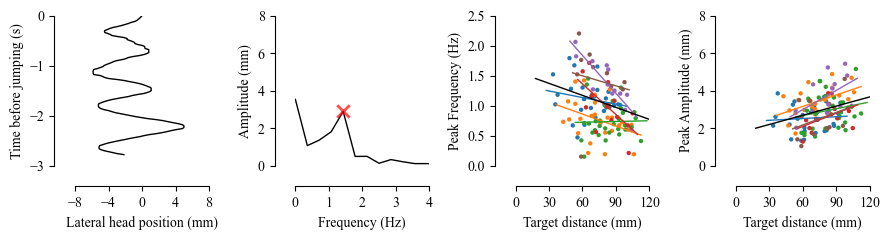

--- Frequency vs Distance Stats DataFrame ---
  Individual ID  body_length  body_mass  sample_size  slope  intercept  \
0           M43       27.743      0.148         28.0 -0.004      1.353   
1           M44       50.077      0.710         26.0 -0.007      1.259   
2           M46       29.566      0.106         30.0  0.000      0.697   
3           M47       43.440      0.529         14.0 -0.017      2.381   
4           M48       36.770      0.317         13.0 -0.021      3.096   
5           M49       50.036      1.065         11.0 -0.006      1.831   

   R_squared p_value  Std_err  
0      0.043   0.289    0.003  
1      0.128   0.073    0.004  
2      0.001   0.904    0.004  
3      0.392   0.017    0.006  
4      0.745  <0.001    0.004  
5      0.028   0.624    0.011  

--- Amplitude vs Distance Stats DataFrame ---
  Individual ID  body_length  body_mass  sample_size  slope  intercept  \
0           M43       27.743      0.148         28.0  0.003      2.319   
1           M44 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal
import statsmodels.formula.api as smf
from matplotlib.ticker import MultipleLocator
from scipy.stats import linregress

def reg(ax, x, y, c):
    if len(x) > 1:
        p = np.polyfit(x, y, 1)
        xr = x.max() - x.min()
        xx = np.linspace(x.min() - 0.1*xr, x.max() + 0.1*xr, 100)
        ax.plot(xx, np.polyval(p, xx), color=c, linewidth = 1)

# ------------------ Load data ------------------
df = pd.read_csv("PeeringKinematics.csv")
df['peering_duration(ms)'] = pd.to_numeric(df['peering_duration(ms)'], errors='coerce')
df = df[df['peering_duration(ms)'] > 1000]

individuals = sorted(df['Individual ID'].unique())

# Color map for individuals
cmap_ind = plt.cm.tab10
colors = {ind: cmap_ind(i % 10) for i, ind in enumerate(individuals)}

# Choose one individual for example trace
example_ind = individuals[1]
df_example = df[df['Individual ID'] == example_ind]
example_row = df_example.iloc[0]

fig, axes = plt.subplots(1, 4, figsize=(9, 2.5))
ax_time, ax_fft, ax_freq, ax_amp = axes

# ------------------ Example trace + FFT ------------------
fs = example_row['framerate(Hz)']
start_idx = int(example_row['start(ms)'] * fs / 1000)
stop_idx  = int(example_row['stop(ms)'] * fs / 1000)

j = pd.read_csv("CSV files with position coordinates/" + example_row['filename'])
segment = j['Head_x'].iloc[start_idx:stop_idx] * example_row['pixelsize(m)'] * 1000

b, a = scipy.signal.butter(3, fs/2.1, 'low', fs=fs)
k = scipy.signal.filtfilt(b, a, segment.values)
t = np.arange(len(k)) / fs

k -= k[-1]
t -= t[-1]

n = len(k)
freqs = np.fft.rfftfreq(n, d=1/fs)
fft_vals = np.abs(np.fft.rfft(k)) * 2 / n

peak_idx = np.argmax(fft_vals[1:]) + 1
peak_freq = freqs[peak_idx]
peak_amp  = fft_vals[peak_idx]

ax_time.plot(k, t, color='k', linewidth=1)
ax_fft.plot(freqs, fft_vals, color='k', linewidth=1)
ax_fft.scatter(peak_freq, peak_amp, color='red', marker='x', s=80, linewidths=2, zorder=6, alpha = 0.7)

# ------------------ Panels 1 & 2 formatting ------------------
ax_time.set_xlabel("Lateral head position (mm)")
ax_time.set_ylabel("Time before jumping (s)")
ax_time.set_xlim(-8, 8)
ax_time.set_ylim(-3, 0)
ax_time.xaxis.set_major_locator(MultipleLocator(4))
ax_time.yaxis.set_major_locator(MultipleLocator(1))
ax_time.spines['bottom'].set_position(('outward', 15))
ax_time.spines['right'].set_visible(False)
ax_time.spines['top'].set_visible(False)
ax_time.spines['left'].set_position(('outward', 15))

ax_fft.set_xlabel("Frequency (Hz)")
ax_fft.set_ylabel("Amplitude (mm)")
ax_fft.set_xlim(0, 4)
ax_fft.set_ylim(0, 8)
ax_fft.xaxis.set_major_locator(MultipleLocator(1))
ax_fft.yaxis.set_major_locator(MultipleLocator(2))
ax_fft.spines['top'].set_visible(False)
ax_fft.spines['right'].set_visible(False)
ax_fft.spines['left'].set_position(('outward', 15))
ax_fft.spines['bottom'].set_position(('outward', 15))

# 🔹 PANELS 3 & 4 WITH MIXED EFFECTS & INDIVIDUAL REGRESSIONS
# Clean data subset for modeling (rename columns to avoid formula syntax errors with parentheses)
df_clean = df.dropna(subset=['TargetDistance(mm)', 'Frequency(Hz)', 'Amplitude(mm)', 'Individual ID']).copy()
df_clean = df_clean.rename(columns={
    'Frequency(Hz)': 'Frequency',
    'Amplitude(mm)': 'Amplitude',
    'TargetDistance(mm)': 'TargetDistance'
})

# Fit Linear Mixed-Effects Models (random intercept per individual) using safe column names
model_freq = smf.mixedlm("Frequency ~ TargetDistance", data=df_clean, groups=df_clean["Individual ID"]).fit()
model_amp = smf.mixedlm("Amplitude ~ TargetDistance", data=df_clean, groups=df_clean["Individual ID"]).fit()

for ind in individuals:
    df_ind = df[df['Individual ID'] == ind]
    color = colors[ind]

    x = df_ind['TargetDistance(mm)'].values
    y_freq = df_ind['Frequency(Hz)'].values
    y_amp  = df_ind['Amplitude(mm)'].values

    ax_freq.scatter(x, y_freq, color=color, s=10, alpha=1, edgecolors='none')
    ax_amp.scatter(x, y_amp, color=color, s=10, alpha=1, edgecolors='none')

    reg(ax_freq, x, y_freq, color)
    reg(ax_amp, x, y_amp, color)

# Plot overall mixed-effects model trend lines (black, thicker)
x_all = df_clean['TargetDistance'].values
xr_all = x_all.max() - x_all.min()
xx_all = np.linspace(x_all.min() - 0.2*xr_all, x_all.max() + 0.2*xr_all, 100)

ax_freq.plot(xx_all, model_freq.fe_params['Intercept'] + model_freq.fe_params['TargetDistance'] * xx_all, color='black', linewidth=1, zorder=7)
ax_amp.plot(xx_all, model_amp.fe_params['Intercept'] + model_amp.fe_params['TargetDistance'] * xx_all, color='black', linewidth=1, zorder=7)


# ------------------ Panel formatting ------------------
ax_freq.set_xlabel("Target distance (mm)")
ax_freq.set_ylabel("Peak Frequency (Hz)")
ax_freq.set_xlim(0, 120)
ax_freq.set_ylim(0, 2.5)
ax_freq.xaxis.set_major_locator(MultipleLocator(30))
ax_freq.yaxis.set_major_locator(MultipleLocator(0.5))
ax_freq.spines['top'].set_visible(False)
ax_freq.spines['right'].set_visible(False)
ax_freq.spines['left'].set_position(('outward', 15))
ax_freq.spines['bottom'].set_position(('outward', 15))

ax_amp.set_xlabel("Target distance (mm)")
ax_amp.set_ylabel("Peak Amplitude (mm)")
ax_amp.set_xlim(0, 120)
ax_amp.set_ylim(0, 8)
ax_amp.xaxis.set_major_locator(MultipleLocator(30))
ax_amp.yaxis.set_major_locator(MultipleLocator(2))
ax_amp.spines['top'].set_visible(False)
ax_amp.spines['right'].set_visible(False)
ax_amp.spines['left'].set_position(('outward', 15))
ax_amp.spines['bottom'].set_position(('outward', 15))

plt.tight_layout()
#plt.savefig("Fig3_PeeringKinematics.svg")
plt.show()

# 📊 INDIVIDUAL REGRESSION STATS TABLES
stats_freq_df = (
    df.groupby("Individual ID")[["TargetDistance(mm)", "Frequency(Hz)", "bodylength(mm)", "mass(g)"]]
    .apply(lambda d: pd.Series({
        "body_length": d["bodylength(mm)"].iloc[0] if "bodylength(mm)" in d and not d["bodylength(mm)"].empty else np.nan,
        "body_mass": d["mass(g)"].iloc[0] if "mass(g)" in d and not d["mass(g)"].empty else np.nan,
        "sample_size": len(d.dropna(subset=["TargetDistance(mm)", "Frequency(Hz)"])),
        **({
            "slope": linregress(d["TargetDistance(mm)"].dropna(), d.dropna(subset=["TargetDistance(mm)", "Frequency(Hz)"])["Frequency(Hz)"]).slope,
            "intercept": linregress(d["TargetDistance(mm)"].dropna(), d.dropna(subset=["TargetDistance(mm)", "Frequency(Hz)"])["Frequency(Hz)"]).intercept,
            "R_squared": linregress(d["TargetDistance(mm)"].dropna(), d.dropna(subset=["TargetDistance(mm)", "Frequency(Hz)"])["Frequency(Hz)"]).rvalue**2,
            "p_value": linregress(d["TargetDistance(mm)"].dropna(), d.dropna(subset=["TargetDistance(mm)", "Frequency(Hz)"])["Frequency(Hz)"]).pvalue,
            "Std_err": linregress(d["TargetDistance(mm)"].dropna(), d.dropna(subset=["TargetDistance(mm)", "Frequency(Hz)"])["Frequency(Hz)"]).stderr
        } if len(d.dropna(subset=["TargetDistance(mm)", "Frequency(Hz)"])) > 1 else {})
    }))
    .dropna(subset=["slope"])
    .reset_index()
    .round(3)
)

stats_amp_df = (
    df.groupby("Individual ID")[["TargetDistance(mm)", "Amplitude(mm)", "bodylength(mm)", "mass(g)"]]
    .apply(lambda d: pd.Series({
        "body_length": d["bodylength(mm)"].iloc[0] if "bodylength(mm)" in d and not d["bodylength(mm)"].empty else np.nan,
        "body_mass": d["mass(g)"].iloc[0] if "mass(g)" in d and not d["mass(g)"].empty else np.nan,
        "sample_size": len(d.dropna(subset=["TargetDistance(mm)", "Amplitude(mm)"])),
        **({
            "slope": linregress(d["TargetDistance(mm)"].dropna(), d.dropna(subset=["TargetDistance(mm)", "Amplitude(mm)"])["Amplitude(mm)"]).slope,
            "intercept": linregress(d["TargetDistance(mm)"].dropna(), d.dropna(subset=["TargetDistance(mm)", "Amplitude(mm)"])["Amplitude(mm)"]).intercept,
            "R_squared": linregress(d["TargetDistance(mm)"].dropna(), d.dropna(subset=["TargetDistance(mm)", "Amplitude(mm)"])["Amplitude(mm)"]).rvalue**2,
            "p_value": linregress(d["TargetDistance(mm)"].dropna(), d.dropna(subset=["TargetDistance(mm)", "Amplitude(mm)"])["Amplitude(mm)"]).pvalue,
            "Std_err": linregress(d["TargetDistance(mm)"].dropna(), d.dropna(subset=["TargetDistance(mm)", "Amplitude(mm)"])["Amplitude(mm)"]).stderr
        } if len(d.dropna(subset=["TargetDistance(mm)", "Amplitude(mm)"])) > 1 else {})
    }))
    .dropna(subset=["slope"])
    .reset_index()
    .round(3)
)

# Format p-values: replace any p_value <= 0.001 with "<0.001"
stats_freq_df["p_value"] = stats_freq_df["p_value"].apply(lambda p: "<0.001" if p <= 0.001 else str(p))
stats_amp_df["p_value"] = stats_amp_df["p_value"].apply(lambda p: "<0.001" if p <= 0.001 else str(p))

print("--- Frequency vs Distance Stats DataFrame ---")
print(stats_freq_df)
print("\n--- Amplitude vs Distance Stats DataFrame ---")
print(stats_amp_df)

# Print model summaries to console
print("--- Frequency MIXED MODEL SUMMARY ---")
print(model_freq.summary())
print("\n--- Amplitude MIXED MODEL SUMMARY ---")
print(model_amp.summary())

## Fig 4

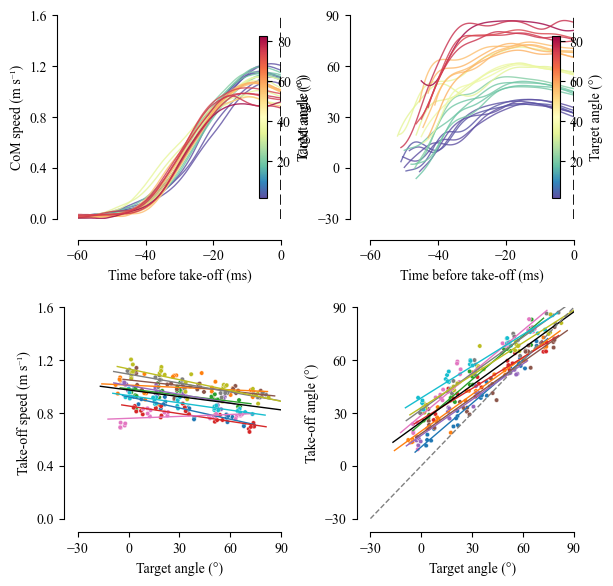

  Individual ID  body_length  body_mass  sample_size  slope  intercept  \
0           M25       49.880      0.473         23.0 -0.003      0.923   
1           M26       63.640      0.595         25.0 -0.001      1.012   
2           M27       41.543      0.345         25.0 -0.002      0.983   
3           M29       44.191      0.621         25.0 -0.002      0.853   
4           M31       61.771      1.299         20.0 -0.002      1.009   
5           M32       49.015      0.748         25.0 -0.001      1.051   
6           M35       23.807      0.063         25.0  0.000      0.760   
7           M36       32.843      0.197         25.0 -0.002      1.095   
8           M37       54.628      0.804         26.0 -0.003      1.134   
9           M39       37.217      0.266         25.0 -0.002      0.932   

   R_squared p_value  Std_err  
0      0.738  <0.001    0.000  
1      0.055    0.26    0.001  
2      0.316   0.003    0.000  
3      0.651  <0.001    0.000  
4      0.720  <0.001    0

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable, Spectral_r
from matplotlib.ticker import MultipleLocator
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.stats import linregress
import statsmodels.formula.api as smf

# Load dataset
df = pd.read_csv('JumpKinematics.csv')
df_scatter = df[df["Experiment"] == "Angle"].dropna(subset=["TargetAngle", "TakeOffSpeed", "TakeOffAngle"])

# Helper: Convert stored list string → array
def convert_to_list(cell):
    return np.array(eval(cell))

# Time-series plotting function
def plot_ts(ax, df, col, cmap, ylims, ystep, xlabel="", ylabel=""):
    norm = Normalize(vmin=df['TargetAngle'].min(),
                     vmax=df['TargetAngle'].max())

    for _, row in df.iterrows():
        series = convert_to_list(row[col])
        takeoff_idx = int(row['takeofftime(ms)'] * 2)

        if col == "Angle_TimeSeries":
            # --- get corresponding speed ---
            speed = convert_to_list(row["Speed_TimeSeries"])

            # --- apply speed threshold mask (no unwrapping) ---
            speed_mask = speed >= 0.05
            series = np.where(speed_mask, series, np.nan)

        time = (np.arange(len(series)) - takeoff_idx) / 2

        ax.plot(time, series,
                color=cmap(norm(row['TargetAngle'])),
                linewidth=1, alpha=0.8)

    ax.axvline(0, color='k', linestyle='--', lw=2)
    ax.set_xlim([-60, 0])
    ax.set_ylim(ylims)
    ax.set_box_aspect(1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.yaxis.set_major_locator(MultipleLocator(ystep))
    sns.despine(ax=ax, offset=15)

    sm = ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    cax = inset_axes(ax, width="4%", height="80%",
                     loc='center right', borderpad=1)
    cbar = plt.colorbar(sm, cax=cax)
    cbar.set_label('Target angle (°)')

# Regression helper
def reg(ax, x, y, c):
    if len(x) > 1:
        p = np.polyfit(x, y, 1)
        xr = x.max() - x.min()
        xx = np.linspace(x.min() - 0.1*xr, x.max() + 0.1*xr, 100)
        ax.plot(xx, np.polyval(p, xx), color=c, linewidth = 1)


# Fit Mixed-Effects Models (Random Slope & Intercept)
# ----------------------------
# Speed vs Angle Mixed Model
md_speed = smf.mixedlm("TakeOffSpeed ~ TargetAngle", df_scatter, 
                       groups=df_scatter["Individual ID"], 
                       re_formula="~TargetAngle")
mdf_speed = md_speed.fit()

# Angle vs Angle Mixed Model
md_angle = smf.mixedlm("TakeOffAngle ~ TargetAngle", df_scatter, 
                       groups=df_scatter["Individual ID"])
mdf_angle = md_angle.fit()

# Figure layout (2x2)
fig, axes = plt.subplots(2, 2, figsize=(6, 6))

ax_ts_speed  = axes[0, 0]
ax_ts_angle  = axes[0, 1]
ax_sc_speed  = axes[1, 0]
ax_sc_angle  = axes[1, 1]

# Top row — Time series (Individual M37)
df_m37 = df[df['Individual ID'] == 'M37']

plot_ts(ax_ts_speed, df_m37, 'Speed_TimeSeries', Spectral_r,
        [0, 1.6], 0.4,
        xlabel='Time before take-off (ms)',
        ylabel='CoM speed (m s⁻¹)')

plot_ts(ax_ts_angle, df_m37, 'Angle_TimeSeries', Spectral_r,
        [-30, 90], 30,
        xlabel='Time before take-off (ms)',
        ylabel='CoM angle (°)')

# Bottom row — Scatter + regression
ids = df_scatter["Individual ID"].unique()
palette = sns.color_palette("tab10", len(ids))

# 1. Speed vs angle
sns.scatterplot(df_scatter, x="TargetAngle", y="TakeOffSpeed",
                hue="Individual ID", palette=palette,
                s=10, legend=False, ax=ax_sc_speed)

for c, i in zip(palette, ids):
    d = df_scatter[df_scatter["Individual ID"] == i]
    reg(ax_sc_speed, d["TargetAngle"], d["TakeOffSpeed"], c)

# Plot Population Mixed-Effects Fit Line (Black)
xr_speed = df_scatter["TargetAngle"].max() - df_scatter["TargetAngle"].min()
xx_speed = np.linspace(df_scatter["TargetAngle"].min() - 0.1*xr_speed, 
                       df_scatter["TargetAngle"].max() + 0.1*xr_speed, 100)
fixed_intercept_speed = mdf_speed.params["Intercept"]
fixed_slope_speed = mdf_speed.params["TargetAngle"]
ax_sc_speed.plot(xx_speed, fixed_intercept_speed + fixed_slope_speed * xx_speed, 
                 color='black', linewidth=1, label='Mixed Model Fit')

ax_sc_speed.set(xlim=(-30, 90), ylim=(0, 1.6),
                xlabel="Target angle (°)",
                ylabel="Take-off speed (m s⁻¹)")
ax_sc_speed.xaxis.set_major_locator(MultipleLocator(30))
ax_sc_speed.yaxis.set_major_locator(MultipleLocator(0.4))
sns.despine(ax=ax_sc_speed, offset=10)

# 2. Angle vs angle
sns.scatterplot(df_scatter, x="TargetAngle", y="TakeOffAngle",
                hue="Individual ID", palette=palette,
                s=10, legend=False, ax=ax_sc_angle)

for c, i in zip(palette, ids):
    d = df_scatter[df_scatter["Individual ID"] == i]
    reg(ax_sc_angle, d["TargetAngle"], d["TakeOffAngle"], c)

# Plot Population Mixed-Effects Fit Line (Black)
xr_angle = df_scatter["TargetAngle"].max() - df_scatter["TargetAngle"].min()
xx_angle = np.linspace(df_scatter["TargetAngle"].min() - 0.1*xr_angle, 
                       df_scatter["TargetAngle"].max() + 0.1*xr_angle, 100)
fixed_intercept_angle = mdf_angle.params["Intercept"]
fixed_slope_angle = mdf_angle.params["TargetAngle"]
ax_sc_angle.plot(xx_angle, fixed_intercept_angle + fixed_slope_angle * xx_angle, 
                 color='black', linewidth=1, label='Mixed Model Fit')

lims = [-30, 90]
ax_sc_angle.plot(lims, lims, linestyle='--', linewidth=1, color='gray')

ax_sc_angle.set(xlim=(-30, 90), ylim=(-30, 90),
                xlabel="Target angle (°)",
                ylabel="Take-off angle (°)")
ax_sc_angle.xaxis.set_major_locator(MultipleLocator(30))
ax_sc_angle.yaxis.set_major_locator(MultipleLocator(30))
sns.despine(ax=ax_sc_angle, offset=10)

# Final layout
plt.tight_layout()
#plt.savefig("Fig4_AngleExperiment.svg")
plt.show()

# --- Speed vs Angle Stats DataFrame ---
stats_speed_df = (
    df_scatter.groupby("Individual ID")[["TargetAngle", "TakeOffSpeed", "bodylength(mm)", "mass(g)"]]
    .apply(lambda d: pd.Series({
        "body_length": d["bodylength(mm)"].iloc[0] if "bodylength(mm)" in d and not d["bodylength(mm)"].empty else np.nan,
        "body_mass": d["mass(g)"].iloc[0] if "mass(g)" in d and not d["mass(g)"].empty else np.nan,
        "sample_size": len(d.dropna(subset=["TargetAngle", "TakeOffSpeed"])),
        **({
            "slope": linregress(d["TargetAngle"], d["TakeOffSpeed"]).slope,
            "intercept": linregress(d["TargetAngle"], d["TakeOffSpeed"]).intercept,
            "R_squared": linregress(d["TargetAngle"], d["TakeOffSpeed"]).rvalue**2,
            "p_value": linregress(d["TargetAngle"], d["TakeOffSpeed"]).pvalue,
            "Std_err": linregress(d["TargetAngle"], d["TakeOffSpeed"]).stderr
        } if len(d.dropna(subset=["TargetAngle","TakeOffSpeed"])) > 1 else {})
    }))
    .dropna(subset=["slope"])
    .reset_index()
    .round(3)
)

# --- Angle vs Angle Stats DataFrame ---
stats_angle_df = (
    df_scatter.groupby("Individual ID")[["TargetAngle", "TakeOffAngle", "bodylength(mm)", "mass(g)"]]
    .apply(lambda d: pd.Series({
        "body_length": d["bodylength(mm)"].iloc[0] if "bodylength(mm)" in d and not d["bodylength(mm)"].empty else np.nan,
        "body_mass": d["mass(g)"].iloc[0] if "mass(g)" in d and not d["mass(g)"].empty else np.nan,
        "sample_size": len(d.dropna(subset=["TargetAngle", "TakeOffAngle"])),
        **({
            "slope": linregress(d["TargetAngle"], d["TakeOffAngle"]).slope,
            "intercept": linregress(d["TargetAngle"], d["TakeOffAngle"]).intercept,
            "R_squared": linregress(d["TargetAngle"], d["TakeOffAngle"]).rvalue**2,
            "p_value": linregress(d["TargetAngle"], d["TakeOffAngle"]).pvalue,
            "Std_err": linregress(d["TargetAngle"], d["TakeOffAngle"]).stderr
        } if len(d.dropna(subset=["TargetAngle","TakeOffAngle"])) > 1 else {})
    }))
    .dropna(subset=["slope"])
    .reset_index()
    .round(3)
)

# Format p-values: replace any p_value <= 0.001 with "<0.001"
stats_speed_df["p_value"] = stats_speed_df["p_value"].apply(lambda p: "<0.001" if p <= 0.001 else str(p))
stats_angle_df["p_value"] = stats_angle_df["p_value"].apply(lambda p: "<0.001" if p <= 0.001 else str(p))

print(stats_speed_df)
print(stats_angle_df)

# Print model summaries to console
print("--- SPEED MIXED MODEL SUMMARY ---")
print(mdf_speed.summary())
print("\n--- ANGLE MIXED MODEL SUMMARY ---")
print(mdf_angle.summary())

## Fig 5

### Fig 5 A

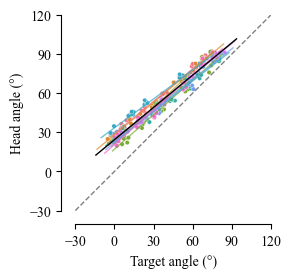

--- INDIVIDUAL REGRESSION STATS ---
  Individual ID  body_length  body_mass  sample_size  Slope  Intercept  \
0           M25       49.880      0.473         23.0  0.830     28.854   
1           M26       63.640      0.595         25.0  0.832     28.128   
2           M27       41.543      0.345         25.0  0.929     21.205   
3           M29       44.191      0.621         25.0  0.882     17.036   
4           M31       61.771      1.299         20.0  0.763     24.998   
5           M32       49.015      0.748         25.0  0.779     22.628   
6           M35       23.807      0.063         25.0  0.740     33.427   
7           M36       32.843      0.197         25.0  0.799     22.113   
8           M37       54.628      0.804         26.0  0.826     23.715   
9           M39       37.217      0.266         25.0  0.887     20.626   

   R_squared p_value  Std_err  
0      0.986  <0.001    0.022  
1      0.987  <0.001    0.020  
2      0.976  <0.001    0.031  
3      0.973  <0.001 

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from scipy.stats import linregress
import statsmodels.formula.api as smf

# Load data
df = pd.read_csv("JumpKinematics.csv")
df = df[df["Experiment"] == "Angle"].dropna(subset=["TargetPlatform_x", "TargetPlatform_y", "Head_ax", "Head_ay", "Head_bx", "Head_by"])

# Colors per individual
ids = df["Individual ID"].unique()
palette = sns.color_palette("husl", len(ids))
color_map = dict(zip(ids, palette))

# Regression helper
def reg(ax, x, y, c):
    if len(x) > 1:
        p = np.polyfit(x, y, 1)
        xr = x.max() - x.min()
        xx = np.linspace(x.min() - 0.1*xr, x.max() + 0.1*xr, 100)
        ax.plot(xx, np.polyval(p, xx), color=c, linewidth=1, alpha=0.7)

# Compute angles
xt = df['Head_bx'] - df['Head_ax']
yt = df['Head_by'] - df['Head_ay']
df["alpha"] = np.degrees(np.arctan2(xt, yt))

tx = (df['Head_ax'] + df['Head_bx']) / 2
ty = (df['Head_ay'] + df['Head_by']) / 2
cx, cy = df['TargetPlatform_x'], df['TargetPlatform_y']
df["phi"] = np.degrees(np.arctan2(cx - tx, cy - ty)) - 90

# Clean dataframe for modeling
df_model = df.dropna(subset=["phi", "alpha"])

# Fit Mixed-Effects Model (Random Slope & Intercept)
md_angle = smf.mixedlm("alpha ~ phi", df_model, 
                       groups=df_model["Individual ID"], 
                       re_formula="~phi")
mdf_angle = md_angle.fit()

# Plot
fig, ax = plt.subplots(figsize=(3,3))

sns.scatterplot(
    data=df_model,
    x="phi",
    y="alpha",
    hue="Individual ID",
    palette=color_map,
    s=10,
    legend=False,
    ax=ax
)

# Per-individual regressions
for i in ids:
    d = df_model[df_model["Individual ID"] == i]
    reg(ax, d["phi"], d["alpha"], color_map[i])

# Plot Population Mixed-Effects Fit Line (Black)
xr_angle = df_model["phi"].max() - df_model["phi"].min()
xx_angle = np.linspace(df_model["phi"].min() - 0.1*xr_angle, 
                       df_model["phi"].max() + 0.1*xr_angle, 100)
fixed_intercept_angle = mdf_angle.params["Intercept"]
fixed_slope_angle = mdf_angle.params["phi"]
ax.plot(xx_angle, fixed_intercept_angle + fixed_slope_angle * xx_angle, 
        color='black', linewidth=1, label='Mixed Model Fit')

# y = x reference
lims = [-30, 120]
ax.plot(lims, lims, linestyle="--", linewidth=1, color="gray")

# Formatting
ax.set(
    xlim=(-30, 120),
    ylim=(-30, 120),
    xlabel="Target angle (°)",
    ylabel="Head angle (°)"
)
ax.set_aspect('equal', adjustable='box')

ax.xaxis.set_major_locator(MultipleLocator(30))
ax.yaxis.set_major_locator(MultipleLocator(30))
sns.despine(ax=ax, offset=10)

plt.tight_layout()
#plt.savefig("Fig5a_HeadAngle.svg", format='svg')
plt.show()

# Regression statistics per individual
stats_angle_df = (
    df_model.groupby("Individual ID")[["phi", "alpha", "bodylength(mm)", "mass(g)"]]
    .apply(lambda d: pd.Series({
        "body_length": d["bodylength(mm)"].iloc[0] if "bodylength(mm)" in d and not d["bodylength(mm)"].empty else np.nan,
        "body_mass": d["mass(g)"].iloc[0] if "mass(g)" in d and not d["mass(g)"].empty else np.nan,
        "sample_size": len(d.dropna(subset=["phi", "alpha"])),
        **({
            "Slope": linregress(d["phi"], d["alpha"]).slope,
            "Intercept": linregress(d["phi"], d["alpha"]).intercept,
            "R_squared": linregress(d["phi"], d["alpha"]).rvalue**2,
            "p_value": linregress(d["phi"], d["alpha"]).pvalue,
            "Std_err": linregress(d["phi"], d["alpha"]).stderr
        } if len(d.dropna(subset=["phi", "alpha"])) > 1 else {})
    }))
    .dropna(subset=["Slope"])
    .reset_index()
    .round(3)
)

# Format p-values: replace any p_value <= 0.001 with "<0.001"
stats_angle_df["p_value"] = stats_angle_df["p_value"].apply(lambda p: "<0.001" if p <= 0.001 else str(p))

#stats_angle_df.to_csv("Stats_Fig5_a.csv", index=False)
print("--- INDIVIDUAL REGRESSION STATS ---")
print(stats_angle_df)

# Print mixed model summary to console
print("\n--- MIXED MODEL SUMMARY ---")
print(mdf_angle.summary())

### Fig 5 C, D, E

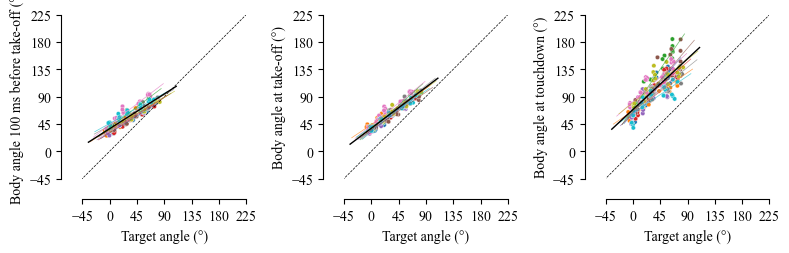

--- STATS PRE100 ---
  Individual ID  body_length  body_mass  sample_size  slope  intercept  \
0           M25       49.880      0.473           21  0.621     30.055   
1           M26       63.640      0.595           25  0.639     36.118   
2           M27       41.543      0.345           25  0.754     39.238   
3           M29       44.191      0.621           25  0.645     30.691   
4           M31       61.771      1.299           20  0.647     32.433   
5           M32       49.015      0.748           25  0.601     34.617   
6           M35       23.807      0.063           25  0.765     43.661   
7           M36       32.843      0.197           25  0.561     42.510   
8           M37       54.628      0.804           26  0.587     36.109   
9           M39       37.217      0.266           25  0.553     45.781   

   R_squared p_value  Std_err  
0      0.964  <0.001    0.027  
1      0.959  <0.001    0.028  
2      0.958  <0.001    0.033  
3      0.949  <0.001    0.031  
4   

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator
from scipy.stats import linregress
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings("ignore")

# Load data
df = pd.read_csv("JumpKinematics.csv")
df = df[df["Experiment"] == "Angle"].reset_index(drop=True)
df = df.dropna(subset=["touchdown(ms)"])

fs = 2  # frames per ms

# Helper: Convert stored list string → array 
def convert_to_list(cell):
    return np.array(eval(cell))

# Extract angles
def extract_angles(row):
    data = convert_to_list(row["BodyAngle_TimeSeries"])
    ti = int(row["takeofftime(ms)"] * fs)
    td = int(row["touchdown(ms)"] * fs)
    p100 = ti - int(100 * fs)
    if p100 < 0 or td >= len(data):
        return pd.Series([np.nan]*3)
    return pd.Series([data[p100], data[ti], data[td]])

df[["body_angle_pre100","body_angle_takeoff","body_angle_touchdown"]] = df.apply(extract_angles, axis=1)

# Drop rows where extracted angles failed
df = df.dropna(subset=[
    "TargetAngle",
    "body_angle_pre100",
    "body_angle_takeoff",
    "body_angle_touchdown"
])

# Fit Mixed-Effects Models (Random Slope & Intercept) for each panel
md_pre100 = smf.mixedlm("body_angle_pre100 ~ TargetAngle", df, 
                        groups=df["Individual ID"], re_formula="~TargetAngle")
mdf_pre100 = md_pre100.fit()

md_takeoff = smf.mixedlm("body_angle_takeoff ~ TargetAngle", df, 
                         groups=df["Individual ID"], re_formula="~TargetAngle")
mdf_takeoff = md_takeoff.fit()

md_touchdown = smf.mixedlm("body_angle_touchdown ~ TargetAngle", df, 
                           groups=df["Individual ID"], re_formula="~TargetAngle")
mdf_touchdown = md_touchdown.fit()

# Plot setup
ids = df["Individual ID"].unique()
palette = dict(zip(ids, sns.color_palette("tab10", len(ids))))

panels = {
    "body_angle_pre100": ("Body angle 100 ms before take-off (°)", mdf_pre100),
    "body_angle_takeoff": ("Body angle at take-off (°)", mdf_takeoff),
    "body_angle_touchdown": ("Body angle at touchdown (°)", mdf_touchdown)
}

fig, axes = plt.subplots(1, 3, figsize=(8,3))

# Regression storage
stats_map = {k: [] for k in panels.keys()}

# Plot panels
for ax, (col, (ylabel, mdf)) in zip(axes, panels.items()):

    sns.scatterplot(data=df, x="TargetAngle", y=col,
                    hue="Individual ID", palette=palette,
                    s=10, legend=False, ax=ax)

    ax.plot([-90, 270], [-90, 270], "--", color="black", lw=0.5)

    for ID in ids:
        d = df[df["Individual ID"] == ID]
        d_sub = d[["TargetAngle", col]].dropna()
        if len(d_sub) < 2:
            continue

        x = d_sub["TargetAngle"].values
        y = d_sub[col].values

        res = linregress(x, y)

        xr = x.max() - x.min()
        xx = np.linspace(x.min()-0.3*xr, x.max()+0.3*xr, 100)

        ax.plot(xx, res.slope*xx + res.intercept,
                color=palette[ID], lw=0.5, alpha=0.7)

        body_len = d["bodylength(mm)"].iloc[0] if "bodylength(mm)" in d and not d["bodylength(mm)"].empty else np.nan
        body_ms = d["mass(g)"].iloc[0] if "mass(g)" in d and not d["mass(g)"].empty else np.nan

        stats_map[col].append({
            "Individual ID": ID,
            "body_length": body_len,
            "body_mass": body_ms,
            "sample_size": len(x),
            "slope": res.slope,
            "intercept": res.intercept,
            "R_squared": res.rvalue**2,
            "p_value": res.pvalue,
            "Std_err": res.stderr
        })

    # Plot Population Mixed-Effects Fit Line (Black)
    xr_all = df["TargetAngle"].max() - df["TargetAngle"].min()
    xx_all = np.linspace(df["TargetAngle"].min() - 0.3*xr_all, 
                         df["TargetAngle"].max() + 0.3*xr_all, 100)
    fixed_intercept = mdf.params["Intercept"]
    fixed_slope = mdf.params["TargetAngle"]
    ax.plot(xx_all, fixed_intercept + fixed_slope * xx_all, 
            color='black', linewidth=1, label='Mixed Model Fit')

    ax.set(xlabel="Target angle (°)", ylabel=ylabel,
           xlim=[-45,225], ylim=[-45,225])
    ax.set_aspect('equal', adjustable='box')
    ax.xaxis.set_major_locator(MultipleLocator(45))
    ax.yaxis.set_major_locator(MultipleLocator(45))
    sns.despine(ax=ax, offset=15)

plt.tight_layout()
#plt.savefig("Fig5_cde_BodyAngles.svg", format="svg")
plt.show()

# Convert stats to DataFrames and round to 3
stats_pre100_df = pd.DataFrame(stats_map["body_angle_pre100"])
stats_takeoff_df = pd.DataFrame(stats_map["body_angle_takeoff"])
stats_touchdown_df = pd.DataFrame(stats_map["body_angle_touchdown"])

for df_stat in [stats_pre100_df, stats_takeoff_df, stats_touchdown_df]:
    if not df_stat.empty:
        df_stat["p_value"] = df_stat["p_value"].apply(lambda p: "<0.001" if p <= 0.001 else str(round(p, 3)))
        # Round numeric columns safely
        numeric_cols = df_stat.select_dtypes(include=[np.number]).columns
        df_stat[numeric_cols] = df_stat[numeric_cols].round(3)

print("--- STATS PRE100 ---")
print(stats_pre100_df)
print("\n--- STATS TAKEOFF ---")
print(stats_takeoff_df)
print("\n--- STATS TOUCHDOWN ---")
print(stats_touchdown_df)

# Print mixed model summaries to console
print("\n--- MIXED MODEL SUMMARY: PRE100 ---")
print(mdf_pre100.summary())
print("\n--- MIXED MODEL SUMMARY: TAKEOFF ---")
print(mdf_takeoff.summary())
print("\n--- MIXED MODEL SUMMARY: TOUCHDOWN ---")
print(mdf_touchdown.summary())

## Fig 6

### Fig 6 A

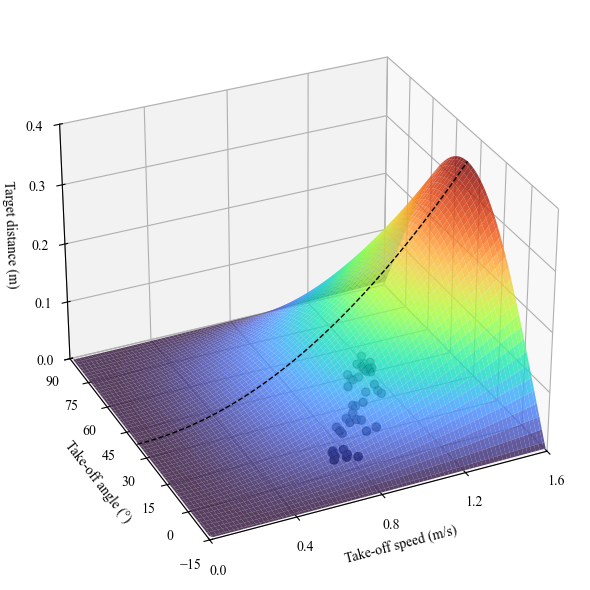

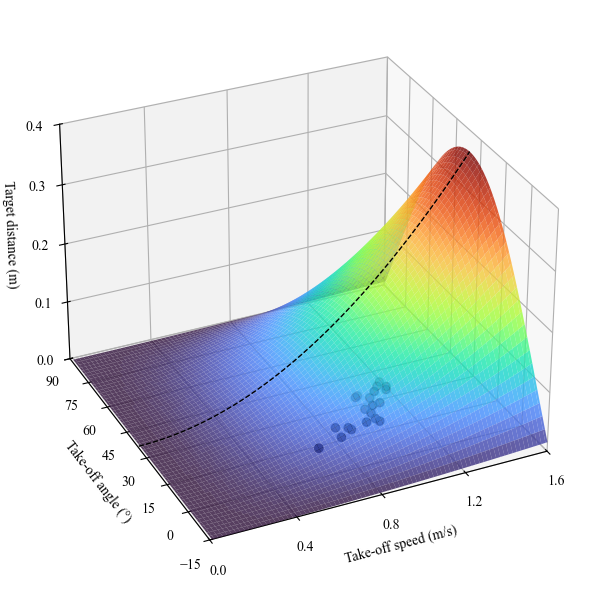

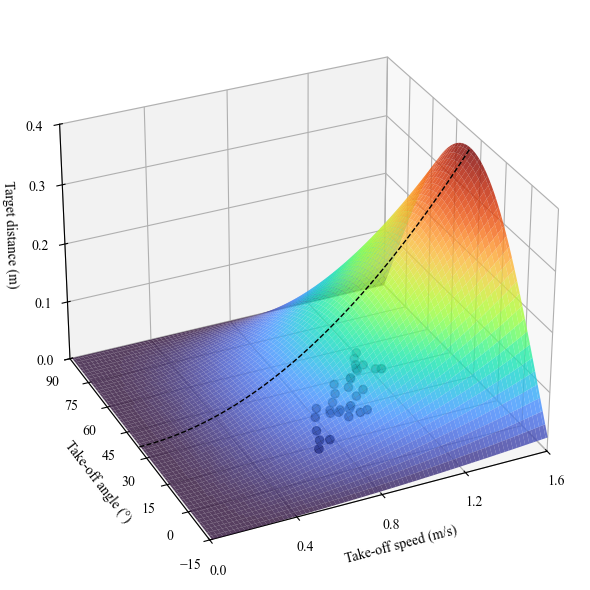

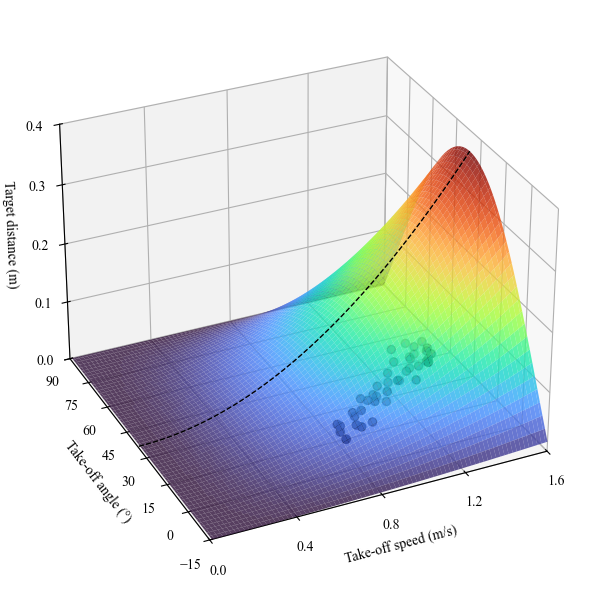

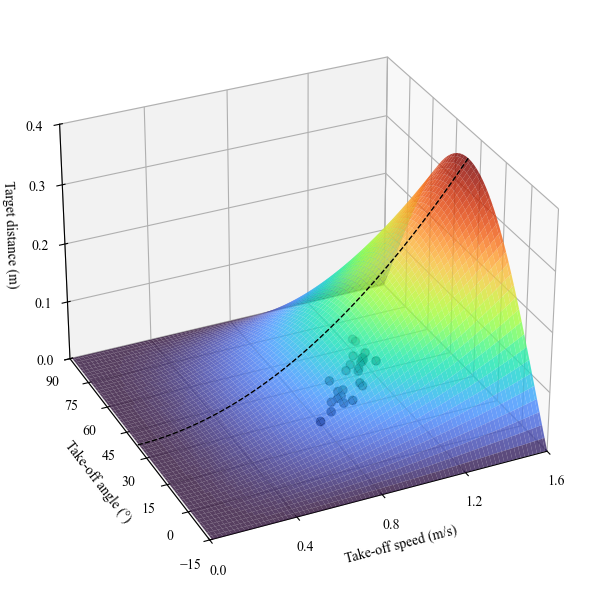

...

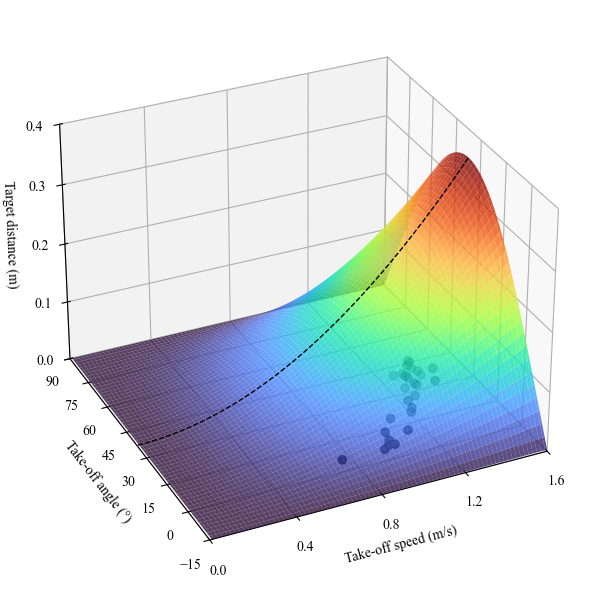

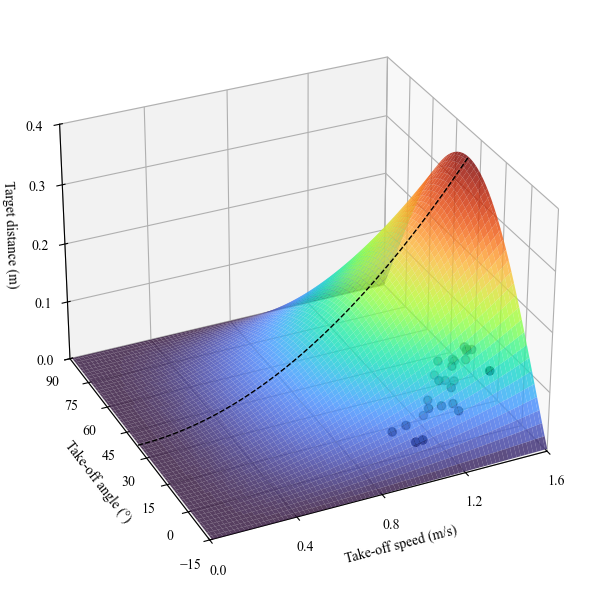

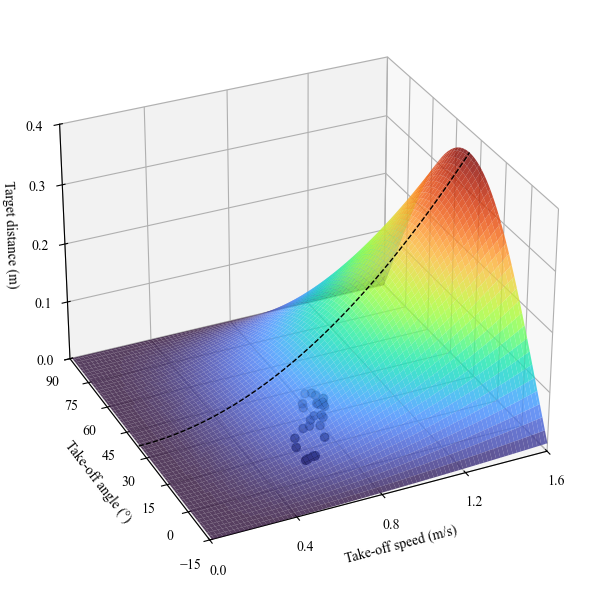

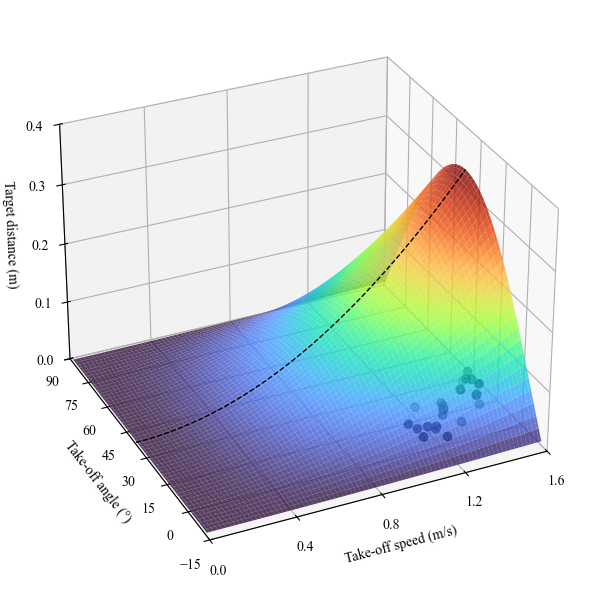

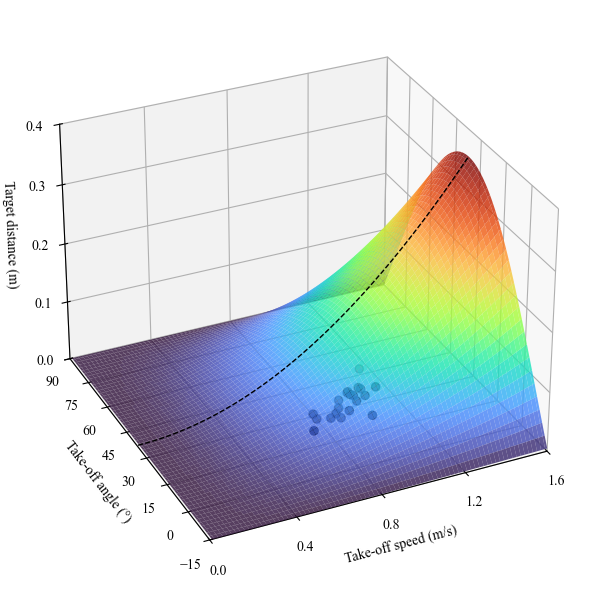

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

g, cutoff = 9.81, 1.6

def calculate_R(phi, theta, u):
    pr, tr = np.radians(phi), np.radians(theta)
    d = np.sin(2*tr - pr) - np.sin(pr)
    R = (u**2 * d) / (g * np.cos(pr)**2)
    R[(d == 0) | (R <= 0) | (R >= cutoff)] = np.nan
    return R

# Load + filter
df = pd.read_csv("JumpKinematics.csv")
df = df[df["Experiment"] == "Distance"]

theta = np.linspace(-15, 90, 120)
u = np.linspace(0, cutoff, 160)
xlim, ylim, zlim = (0, 1.6), (-15, 90), (0, 0.4)

Tg, Ug = np.meshgrid(theta, u, indexing="ij")



for ind, d in df.groupby("Individual ID"):

    phi_mean = d["TargetAngle_COM"].mean()
    R = calculate_R(phi_mean, Tg, Ug)

    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection="3d")

    R[(Ug < xlim[0]) | (Ug > xlim[1]) |
      (Tg < ylim[0]) | (Tg > ylim[1]) |
      (R < zlim[0]) | (R > zlim[1])] = np.nan

    # Surface for this individual
    surf = ax.plot_surface(
        Ug, Tg, R,
        cmap="turbo",
        edgecolor="none",
        linewidth=0,
        antialiased=True,
        alpha=0.8,
        rcount=100, ccount=100,
        zorder=1
    )

    # Individual data points (on top)
    x = d["TakeOffSpeed"].values
    y = d["TakeOffAngle"].values
    z = d["TargetDistance_COM"].values

    ax.scatter(x, y, z, color="black", s=35, zorder=20)

    # Optimal trajectory line for this individual
    theta_opt = 45 + phi_mean / 2
    u_line = np.linspace(0, cutoff, 300)
    R_opt = calculate_R(phi_mean, np.full_like(u_line, theta_opt), u_line)
    R_opt[(u_line < xlim[0]) | (u_line > xlim[1]) | (R_opt > zlim[1])] = np.nan
    ax.plot(u_line, np.full_like(u_line, theta_opt), R_opt, "k--", lw=1, zorder=15)

    ax.set(xlabel="Take-off speed (m/s)",
        ylabel="Take-off angle (°)",
        zlabel="Target distance (m)",
        xlim=xlim, ylim=ylim, zlim=zlim)

    ax.xaxis.set_major_locator(MultipleLocator(0.4))
    ax.yaxis.set_major_locator(MultipleLocator(15))
    ax.zaxis.set_major_locator(MultipleLocator(0.1))

    ax.view_init(elev=30, azim=245)

    plt.tight_layout()
    #plt.savefig(f"Fig_6_a_{ind}.svg")
    plt.show()


### Fig 6 B, C

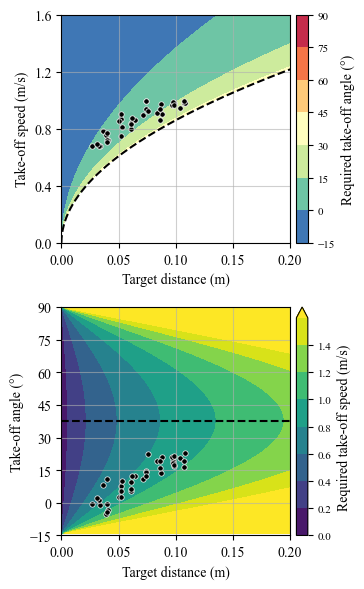

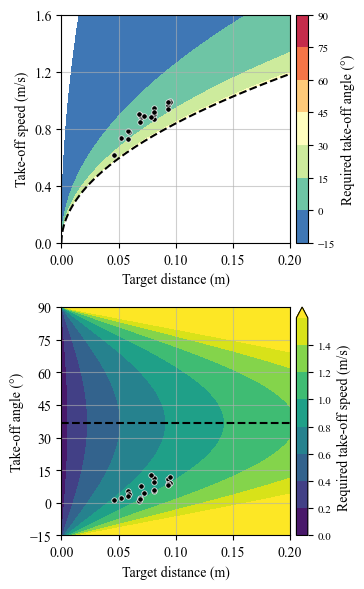

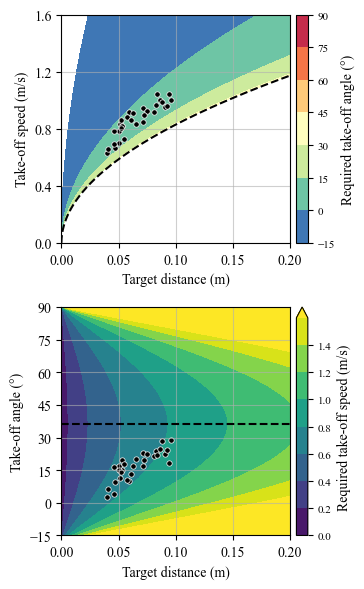

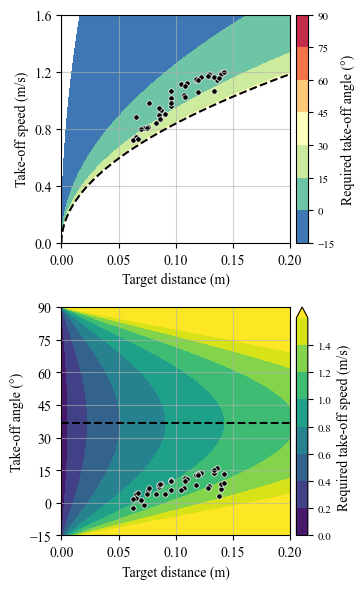

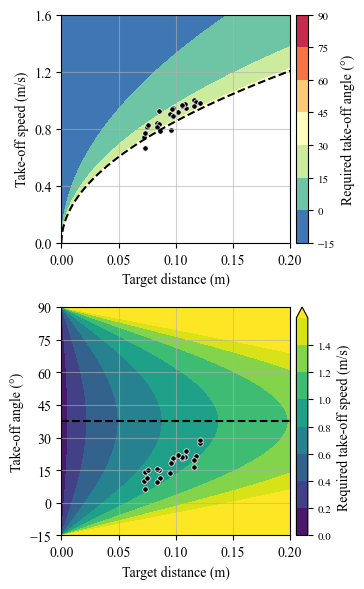

...

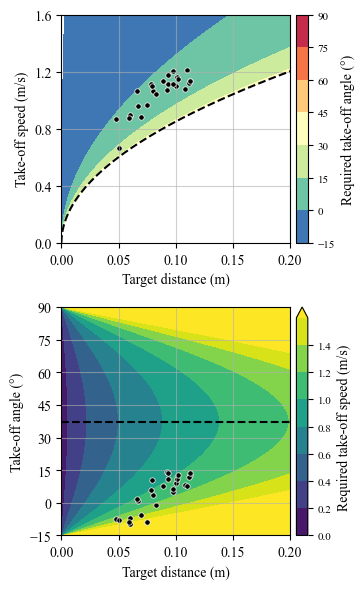

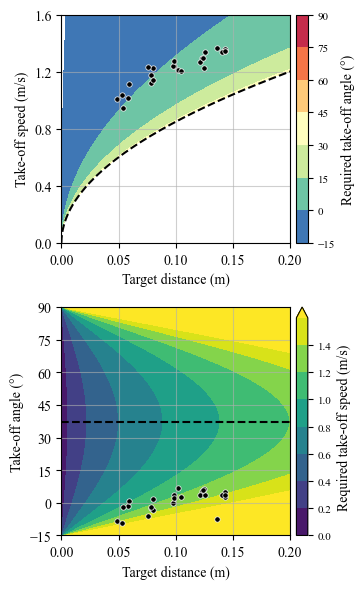

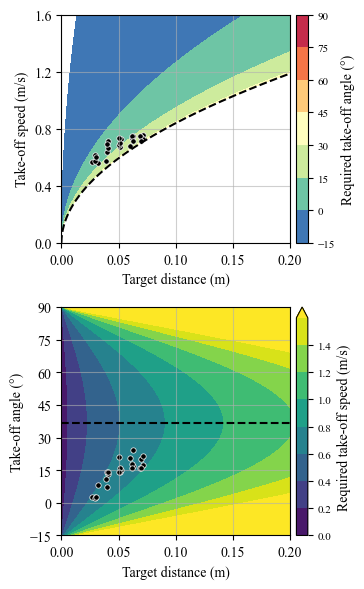

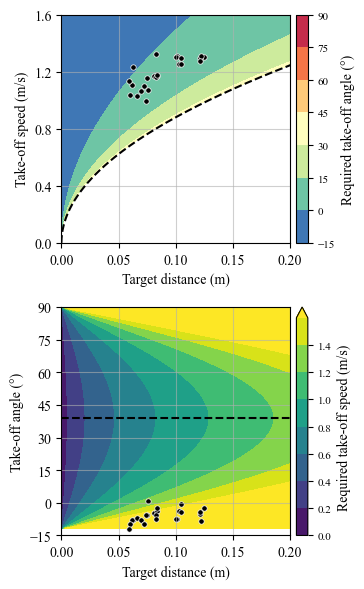

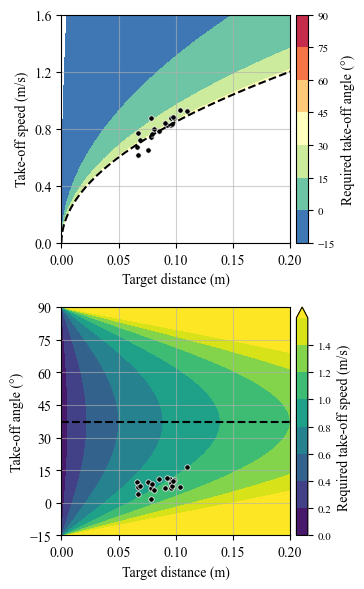

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import matplotlib.colors as mcolors

g = 9.81

# Forward model
def calculate_R(phi, theta, u):
    pr, tr = np.radians(phi), np.radians(theta)
    d = np.sin(2*tr - pr) - np.sin(pr)
    R = (u**2 * d) / (g * np.cos(pr)**2)
    R[(d <= 0) | (R <= 0)] = np.nan
    return R

# Inverse model: angle
def solve_theta(phi, R, u):
    pr = np.radians(phi)
    term = (g * R * np.cos(pr)**2) / (u**2) + np.sin(pr)

    valid = (term >= -1) & (term <= 1) & (u > 0)
    theta1 = np.full_like(term, np.nan)
    theta2 = np.full_like(term, np.nan)

    theta1[valid] = 0.5 * (np.degrees(np.arcsin(term[valid])) + phi)
    theta2[valid] = 0.5 * (180 - np.degrees(np.arcsin(term[valid])) + phi)

    theta = np.where(theta1 <= 90, theta1, theta2)
    theta[(theta < -90) | (theta > 90)] = np.nan
    return theta

# Inverse model: speed
def solve_speed(phi, R, theta):
    pr, tr = np.radians(phi), np.radians(theta)
    denom = np.sin(2*tr - pr) - np.sin(pr)

    with np.errstate(divide='ignore', invalid='ignore'):
        u = np.sqrt((g * R * np.cos(pr)**2) / denom)

    u[(denom <= 1e-6) | (u <= 0)] = np.nan
    return u

# Load data
df = pd.read_csv("JumpKinematics.csv")
df = df[df["Experiment"] == "Distance"]

# Grids
R_grid = np.linspace(0, 1, 1000)
u_grid = np.linspace(0.001, 10, 1000)
theta_grid = np.linspace(-15, 90, 200)

Rg_u, Ug = np.meshgrid(R_grid, u_grid)
Rg_t, Tg = np.meshgrid(R_grid, theta_grid)

for ind, d in df.groupby("Individual ID"):

    phi_mean = d["TargetAngle_COM"].mean()

    Theta_surface = solve_theta(phi_mean, Rg_u, Ug)
    Speed_surface = solve_speed(phi_mean, Rg_t, Tg)

    theta_opt = 45 + phi_mean / 2
    u_line = np.linspace(0.001, 10, 1000)
    R_opt = calculate_R(phi_mean, np.full_like(u_line, theta_opt), u_line)
    theta_opt_line = np.full_like(R_opt, theta_opt)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(4, 6))

    # LEFT: Distance vs Speed (ANGLE field)
    cf1 = ax1.contourf(Rg_u, Ug, Theta_surface, levels=np.arange(-15, 91, 15), cmap="Spectral_r")
    ax1.scatter(d["TargetDistance_COM"], d["TakeOffSpeed"], color="black", edgecolors="white", linewidth=0.5, s=15)
    ax1.plot(R_opt, u_line, "k--", lw=1.5)
    ax1.set_xlabel("Target distance (m)")
    ax1.set_ylabel("Take-off speed (m/s)")
    ax1.set_box_aspect(1)
    ax1.set_xlim(0, 0.2)
    ax1.set_ylim(0, 1.6)
    ax1.xaxis.set_major_locator(MultipleLocator(0.05))
    ax1.yaxis.set_major_locator(MultipleLocator(0.4))
    ax1.grid(True, alpha=0.6)

    cbar1 = fig.colorbar(cf1, ax=ax1, fraction=0.045, pad=0.02)
    cbar1.set_label("Required take-off angle (°)")
    cbar1.set_ticks(np.arange(-15, 91, 15))
    cbar1.ax.tick_params(labelsize=8)

    # RIGHT: Distance vs Angle (SPEED field)
    norm = mcolors.Normalize(vmin=0, vmax=1.6)
    cf2 = ax2.contourf(Rg_t, Tg, Speed_surface, levels=np.linspace(0, 1.6, 9), cmap="viridis", norm=norm, extend="max")
    ax2.scatter(d["TargetDistance_COM"], d["TakeOffAngle"], color="black", edgecolors="white", linewidth=0.5, s=15)
    ax2.plot(R_opt, theta_opt_line, "k--", lw=1.5)
    ax2.set_xlabel("Target distance (m)")
    ax2.set_ylabel("Take-off angle (°)")
    ax2.set_box_aspect(1)
    ax2.set_xlim(0, 0.2)
    ax2.set_ylim(-15, 90)
    ax2.xaxis.set_major_locator(MultipleLocator(0.05))
    ax2.yaxis.set_major_locator(MultipleLocator(15))
    ax2.grid(True, alpha=0.6)
    
    cbar2 = fig.colorbar(cf2, ax=ax2, fraction=0.045, pad=0.02)
    cbar2.set_label("Required take-off speed (m/s)")
    cbar2.set_ticks(np.arange(0, 1.6, 0.2))
    cbar2.ax.tick_params(labelsize=8)

    plt.tight_layout()
    #plt.savefig(f"Fig_6_b_c_{ind}.svg")
    #plt.savefig(f"Fig_6_b_c_{ind}.png", dpi=600)
    plt.show()


### Fig 6 D

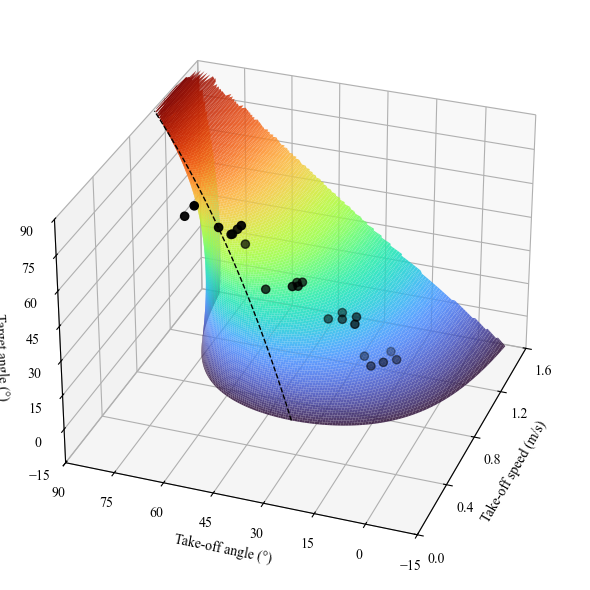

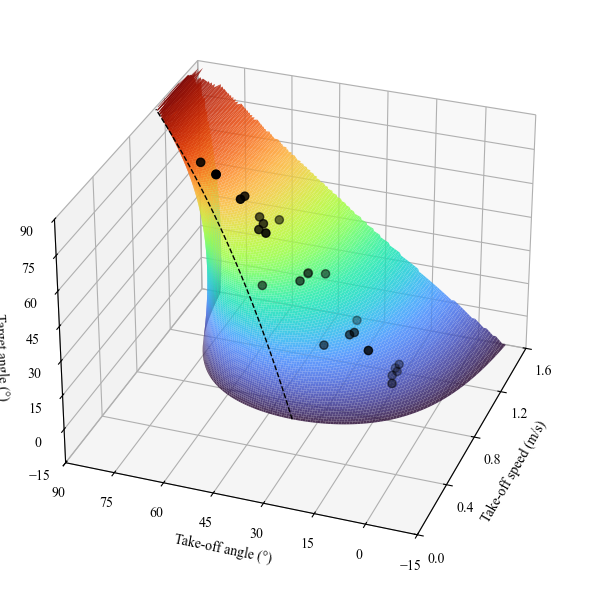

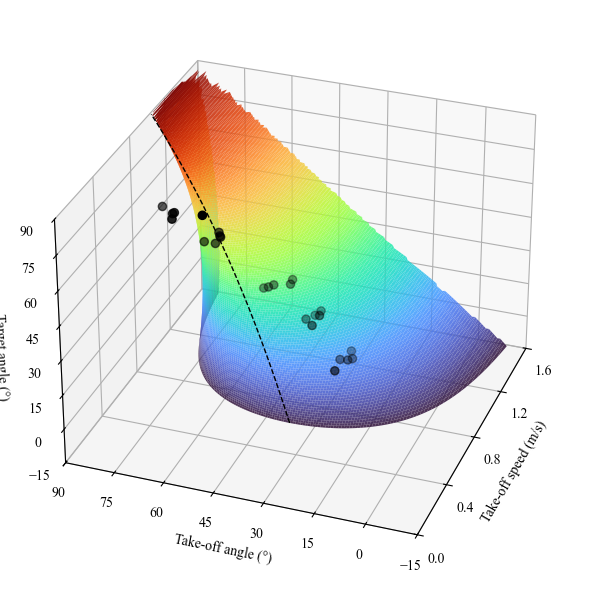

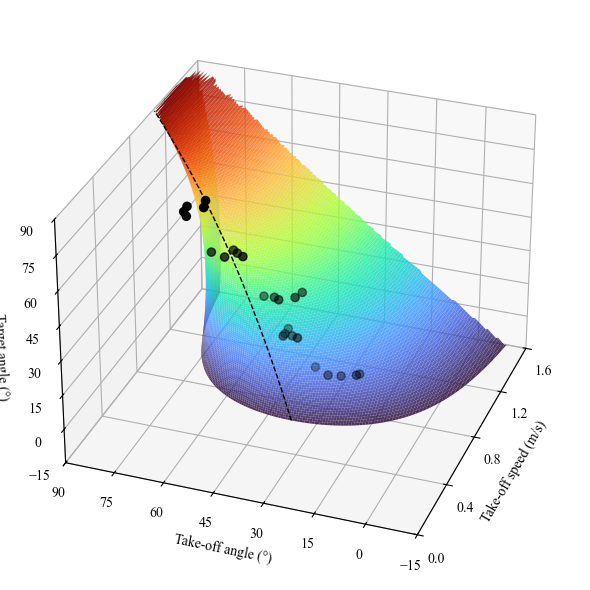

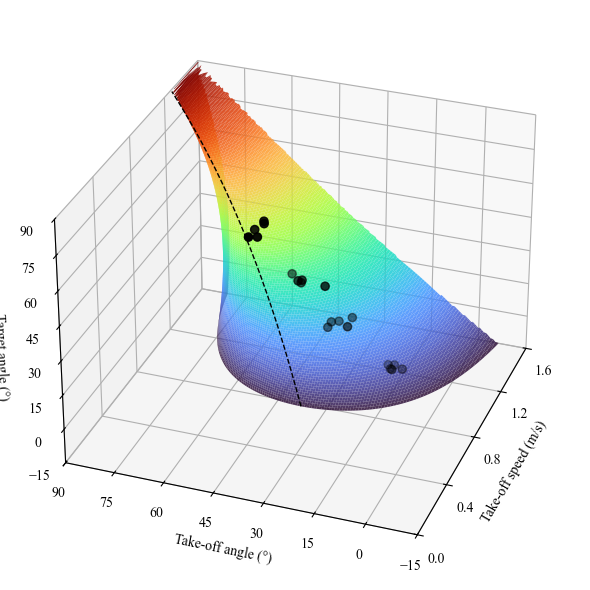

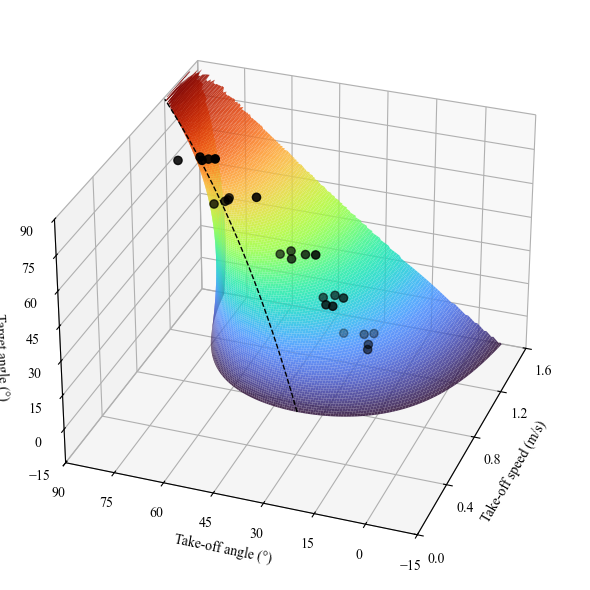

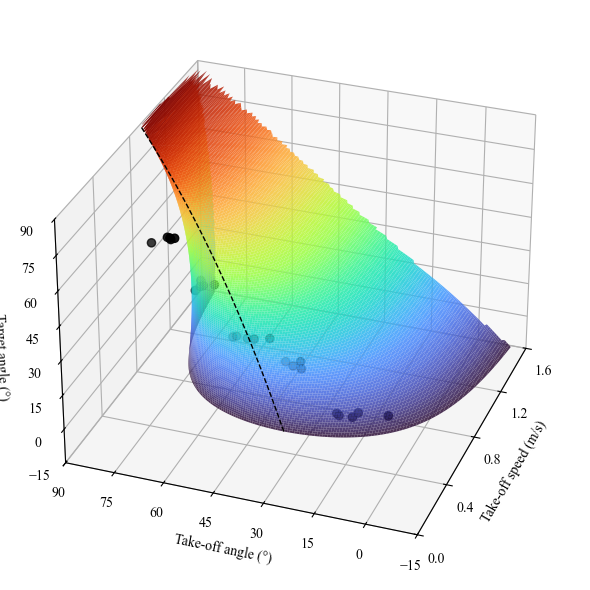

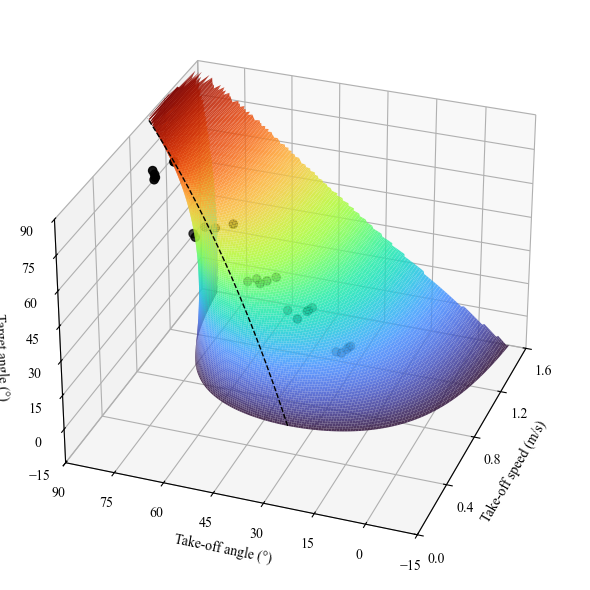

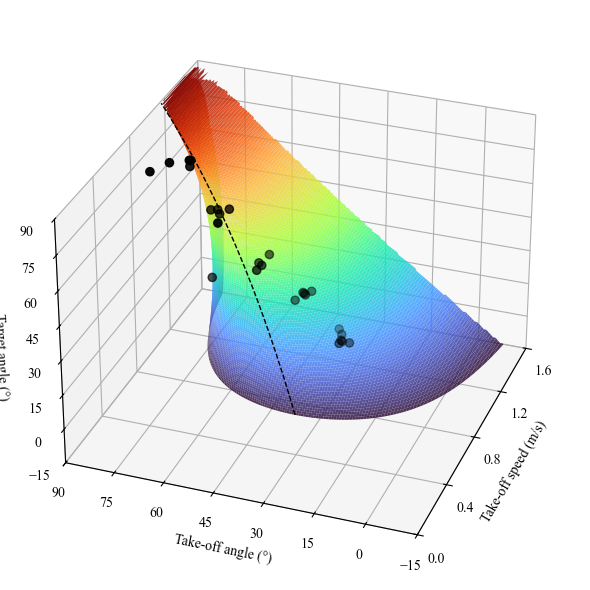

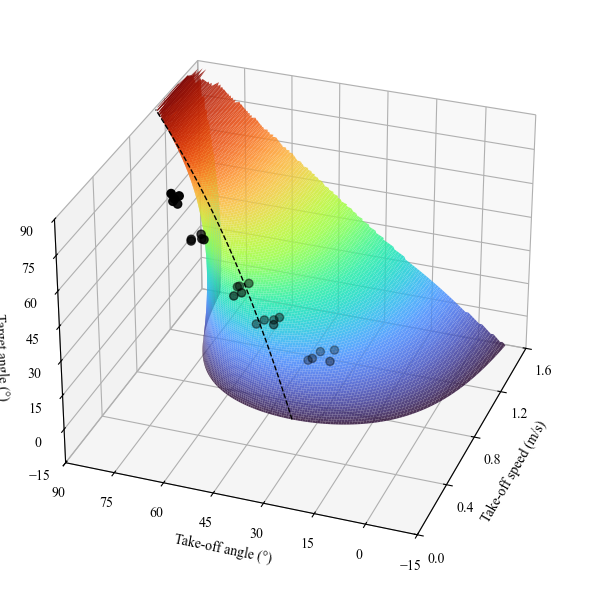

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

g, cutoff = 9.81, 1.6

def calculate_u(theta, R, phi, cutoff_u):
    theta_rad = np.radians(theta)
    phi_rad = np.radians(phi)
    denom = np.sin(2*theta_rad - phi_rad) - np.sin(phi_rad)
    denom = np.where(denom == 0, np.nan, denom)
    u = np.sqrt((g * R * np.cos(phi_rad)**2) / denom)
    return np.where((u >= cutoff_u) | (u < 0), np.nan, u)

# Load + filter
df = pd.read_csv("JumpKinematics.csv")
df = df[df["Experiment"] == "Angle"]

# Axes ranges
theta, phi = np.linspace(-15, 90, 1000), np.linspace(-15, 90, 1000)
xlim, ylim, zlim = (0, 1.6), (-15, 90), (-15, 90)

for ind, d in df.groupby("Individual ID"):

    R_mean = d["TargetDistance_COM"].mean()
    Tg, Pg = np.meshgrid(theta, phi, indexing="ij")
    Ug = calculate_u(Tg, R_mean, Pg, cutoff)

    Ug[(Ug < xlim[0]) | (Ug > xlim[1])] = np.nan
    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection="3d")

    # Surface: speed as function of theta & phi
    surf = ax.plot_surface(
        Ug, Tg, Pg,
        cmap="turbo",
        edgecolor="none",
        linewidth=0,
        antialiased=True,
        alpha=0.85,
        rcount=150, ccount=150
    )

    # Individual data points (on top)
    x = d["TakeOffSpeed"].values
    y = d["TakeOffAngle"].values
    z = d["TargetAngle_COM"].values

    ax.scatter(x, y, z, color="black", s=35, zorder=20)

    # Optimal take-off angle
    phi_line = np.linspace(-15, 90, 200)
    theta_opt = 45 + phi_line / 2
    u_opt = calculate_u(theta_opt, R_mean, phi_line, cutoff)

    ax.plot(u_opt, theta_opt, phi_line, "k--", lw=1, zorder=10)

    # Labels
    ax.set(
        xlabel="Take-off speed (m/s)",
        ylabel="Take-off angle (°)",
        zlabel="Target angle (°)",
        xlim=xlim, ylim=ylim, zlim=zlim
    )

    ax.xaxis.set_major_locator(MultipleLocator(0.4))
    ax.yaxis.set_major_locator(MultipleLocator(15))
    ax.zaxis.set_major_locator(MultipleLocator(15))

    ax.view_init(elev=30, azim=200)

    plt.tight_layout()
    #plt.savefig(f"Fig_6_d_{ind}.svg")
    plt.show()


### Fig 6 E, F

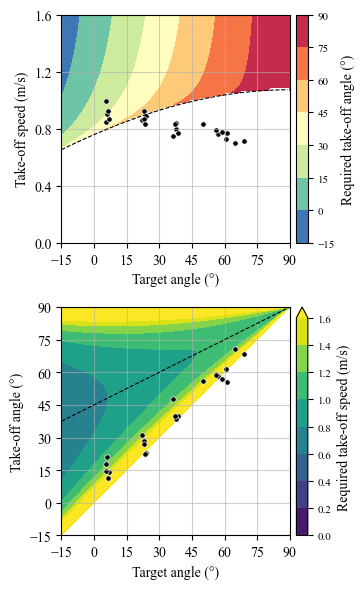

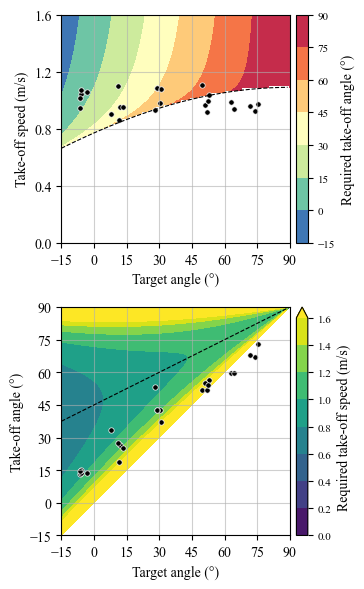

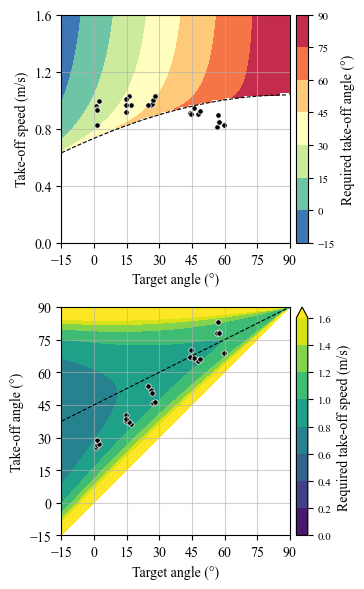

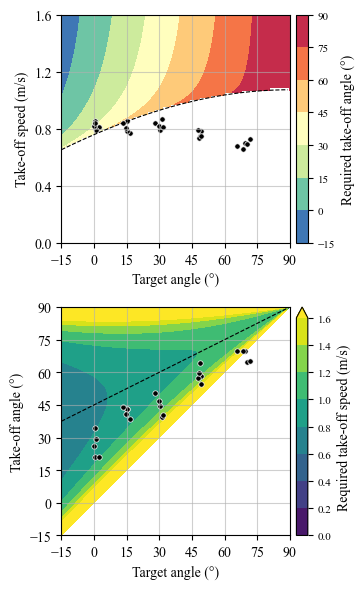

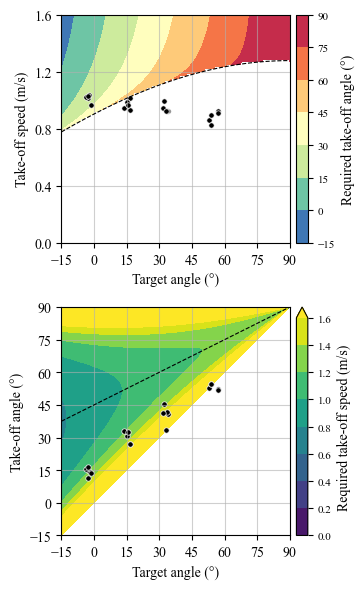

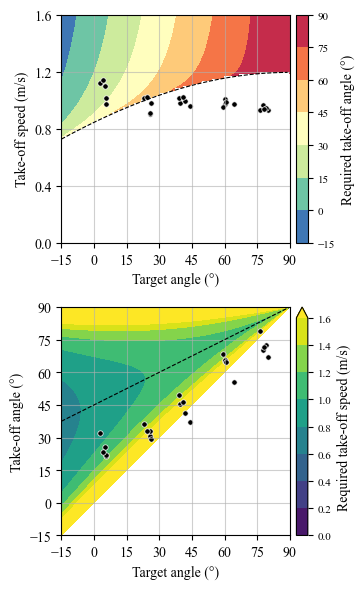

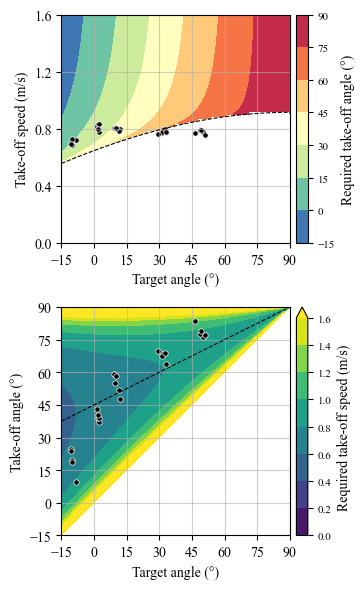

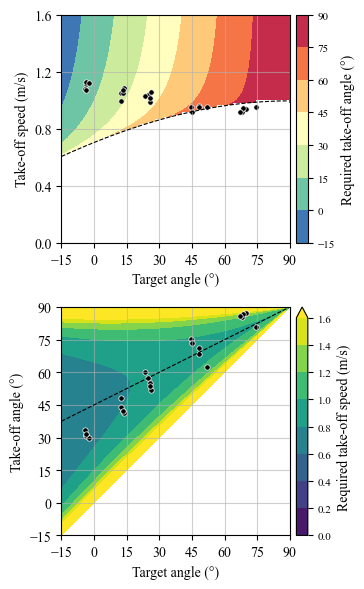

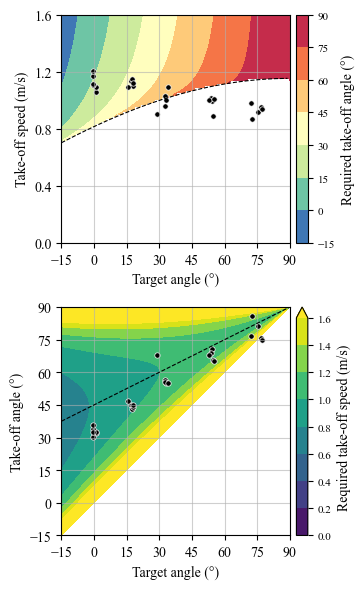

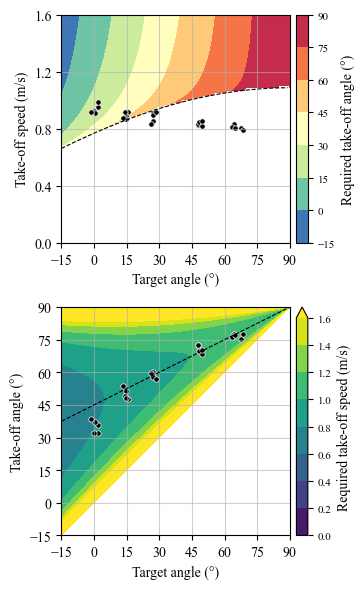

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import matplotlib.colors as mcolors

g = 9.81

# Forward model
def calculate_R(phi, theta, u):
    pr, tr = np.radians(phi), np.radians(theta)
    d = np.sin(2*tr - pr) - np.sin(pr)
    R = (u**2 * d) / (g * np.cos(pr)**2)
    R[(d <= 0) | (R <= 0)] = np.nan
    return R

# Inverse model: required take-off angle
def solve_theta(phi, R, u):
    pr = np.radians(phi)
    term = (g * R * np.cos(pr)**2) / (u**2) + np.sin(pr)

    valid = (term >= -1) & (term <= 1) & (u > 0)
    theta1 = np.full_like(term, np.nan)
    theta2 = np.full_like(term, np.nan)

    theta1[valid] = 0.5 * (np.degrees(np.arcsin(term[valid])) + np.degrees(pr[valid]))
    theta2[valid] = 0.5 * (180 - np.degrees(np.arcsin(term[valid])) + np.degrees(pr[valid]))

    theta = np.where(theta1 <= 90, theta1, theta2)
    theta[(theta < -90) | (theta > 90)] = np.nan
    return theta

# Inverse model: required speed
def solve_speed(phi, R, theta):
    pr, tr = np.radians(phi), np.radians(theta)
    denom = np.sin(2*tr - pr) - np.sin(pr)

    with np.errstate(divide='ignore', invalid='ignore'):
        u = np.sqrt((g * R * np.cos(pr)**2) / denom)

    u[(denom <= 1e-6) | (u <= 0)] = np.nan
    return u

# Load data
df = pd.read_csv("JumpKinematics.csv")
df = df[df["Experiment"] == "Angle"]

# Grids
phi_grid = np.linspace(-15, 90, 400)
u_grid = np.linspace(0.001, 10, 600)
theta_grid = np.linspace(-15, 90, 400)

Phig_u, Ug = np.meshgrid(phi_grid, u_grid)
Phig_t, Tg = np.meshgrid(phi_grid, theta_grid)

for ind, d in df.groupby("Individual ID"):

    R_mean = d["TargetDistance_COM"].mean()

    # Surfaces
    Theta_surface = solve_theta(Phig_u, R_mean, Ug)
    Speed_surface = solve_speed(Phig_t, R_mean, Tg)

    # Theoretical ridges
    theta_opt_curve = 45 + phi_grid / 2  # range-maximizing angle

    # Minimum speed ridge (computed directly)
    phi_rad = np.radians(phi_grid)
    theta_rad = np.radians(theta_opt_curve)
    denom = np.sin(2*theta_rad - phi_rad) - np.sin(phi_rad)
    u_opt_curve = np.sqrt((g * R_mean * np.cos(phi_rad)**2) / denom)
    u_opt_curve[(denom <= 1e-4) | (u_opt_curve <= 0)] = np.nan

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(4, 6))

    # TOP
    cf1 = ax1.contourf(Phig_u, Ug, Theta_surface, levels=np.arange(-15, 91, 15), cmap="Spectral_r")
    ax1.scatter(d["TargetAngle_COM"], d["TakeOffSpeed"], color="black", edgecolors="white", linewidth=0.5, s=15)
    ax1.plot(phi_grid, u_opt_curve, "k--", lw=0.8, zorder=7)
    ax1.set_xlabel("Target angle (°)")
    ax1.set_ylabel("Take-off speed (m/s)")
    ax1.set_xlim(-15, 90)
    ax1.set_ylim(0, 1.6)
    ax1.set_box_aspect(1)
    ax1.xaxis.set_major_locator(MultipleLocator(15))
    ax1.yaxis.set_major_locator(MultipleLocator(0.4))
    ax1.grid(True, alpha=0.6)

    cbar1 = fig.colorbar(cf1, ax=ax1, fraction=0.045, pad=0.02)
    cbar1.set_label("Required take-off angle (°)")
    cbar1.set_ticks(np.arange(-15, 91, 15))
    cbar1.ax.tick_params(labelsize=8)

    # BOTTOM
    norm = mcolors.Normalize(vmin=0, vmax=1.6)

    cf2 = ax2.contourf(Phig_t, Tg, Speed_surface, levels=np.linspace(0, 1.6, 9), cmap="viridis", norm=norm, extend="max")
    ax2.scatter(d["TargetAngle_COM"], d["TakeOffAngle"], color="black", edgecolors="white", linewidth=0.5, s=15)
    ax2.plot(phi_grid, theta_opt_curve, "k--", lw=0.8, zorder=7)
    ax2.set_xlabel("Target angle (°)")
    ax2.set_ylabel("Take-off angle (°)")
    ax2.set_xlim(-15, 90)
    ax2.set_ylim(-15, 90)
    ax2.set_box_aspect(1)
    ax2.xaxis.set_major_locator(MultipleLocator(15))
    ax2.yaxis.set_major_locator(MultipleLocator(15))
    ax2.grid(True, alpha=0.6)

    cbar2 = fig.colorbar(cf2, ax=ax2, fraction=0.045, pad=0.02, extend="max")
    cbar2.set_label("Required take-off speed (m/s)")
    cbar2.set_ticks(np.arange(0, 1.7, 0.2))
    cbar2.ax.tick_params(labelsize=8)

    plt.tight_layout()
    #plt.savefig(f"Fig_6_e_f{ind}.svg")
    plt.savefig(f"Fig_6_e_f{ind}.png", dpi=600)
    plt.show()


## Fig S

Slope: -4.5768, Intercept: 394.9232, R2: 0.4796, P: 4.2175e-03, Err: 1.3224


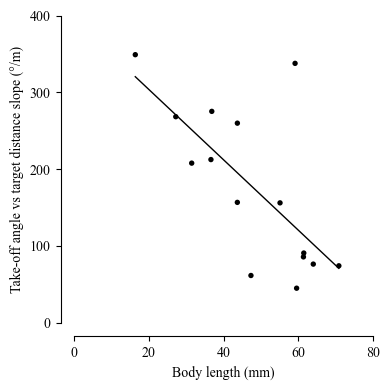

In [2]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import linregress

# Load dataset and extract distance experiment slopes
df = pd.read_csv("JumpKinematics.csv").rename(columns={"bodylength(mm)": "BodyLength"})
d = df[df["Experiment"] == "Distance"]
slopes = pd.DataFrame([
    {"BodyLength": g["BodyLength"].iloc[0], "Slope": linregress(g["TargetDistance"], g["TakeOffAngle"]).slope}
    for _, g in d.groupby("Individual ID") if len(g) > 1
])

# Print Regression Stats
res = linregress(slopes["BodyLength"], slopes["Slope"])
print(f"Slope: {res.slope:.4f}, Intercept: {res.intercept:.4f}, R2: {res.rvalue**2:.4f}, P: {res.pvalue:.4e}, Err: {res.stderr:.4f}")

# Plotting
fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(slopes["BodyLength"], slopes["Slope"], color="black", s=15, edgecolors="none")

if len(slopes) > 1:
    p = np.polyfit(slopes["BodyLength"], slopes["Slope"], 1)
    xx = np.linspace(slopes["BodyLength"].min(), slopes["BodyLength"].max(), 100)
    ax.plot(xx, np.polyval(p, xx), color="black", linewidth=1)

ax.set(xlabel="Body length (mm)", ylabel="Take-off angle vs target distance slope (°/m)", xlim=(0, 80), ylim=(0, 400))
ax.xaxis.set_major_locator(ticker.MultipleLocator(20))
ax.yaxis.set_major_locator(ticker.MultipleLocator(100))
sns.despine(ax=ax, offset=10)

plt.tight_layout()
#plt.savefig("Fig_BodySize.svg", format="svg", bbox_inches="tight")
plt.show()

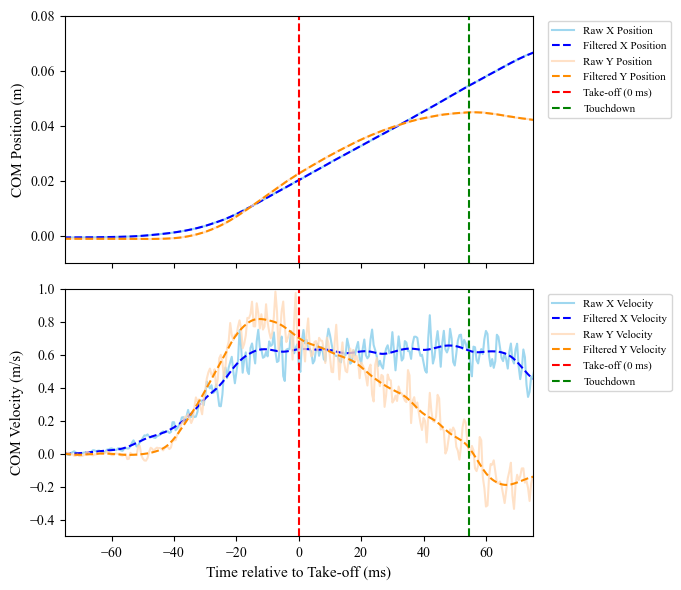

In [ ]:
import scipy.signal
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def read_filter_df(filename):
    """
    Read data from a CSV file, apply a low-pass Butterworth filter, and return filtered data.
    """
    df = pd.read_csv(filename)
    b, a = scipy.signal.butter(3, 75, 'low', fs=2000)
    return df.apply(lambda col: scipy.signal.filtfilt(b, a, col))

def calculate_com_position(df, row):
    """
    Calculate the center of mass (COM) coordinate positions (x, y) in meters.
    """
    pixel_size = row['pixelsize(m)']
    
    x_com = (
        ((df['Head_x'] + df['ProThorax_x']) / 2) * row['Head_Mass'] +
        ((df['ProThorax_x'] + df['MesoThorax_x']) / 2) * row['ProThorax_Mass'] +
        ((df['MesoThorax_x'] + df['MetaThorax_x']) / 2) * row['MetaThorax_Mass'] +
        ((df['MetaThorax_x'] + df['Abdomen_x']) / 2) * row['MetaThorax_Mass'] +
        ((df['Abdomen_x'] + df['Abdomen_Mid_x'] + df['Abdomen_Tip_x']) / 3) * row['Abdomen_Mass'] +
        ((df['FL_Tibia_x'] + df['FL_Femur_x']) / 2) * (row['FL_Tib+Tar_Mass'] * 2) +
        ((df['FL_Femur_x'] + df['FL_Trochanter_x']) / 2) * (row['FL_Fem_Mass'] * 2) +
        ((df['FL_Trochanter_x'] + df['FL_Coxa_x']) / 2) * (row['FL_Cox+Tro_Mass'] * 2) +
        ((df['ML_Tarsi_x'] + df['ML_Femur_x']) / 2) * (row['ML_Tib+Tar_Mass'] * 2) +
        ((df['ML_Femur_x'] + df['ML_Trochanter_x']) / 2) * (row['ML_Fem_Mass'] * 2) +
        ((df['ML_Trochanter_x'] + df['ML_Coxa_x']) / 2) * (row['ML_Tro_Mass'] * 2) +
        ((df['HL_Tarsi_x'] + df['HL_Femur_x']) / 2) * (row['HL_Tib+Tar_Mass'] * 2) +
        ((df['HL_Femur_x'] + df['HL_Trochanter_x']) / 2) * (row['HL_Fem_Mass'] * 2) +
        ((df['HL_Trochanter_x'] + df['HL_Coxa_x']) / 2) * (row['HL_Tro_Mass'] * 2)
    ) / row['mass(g)']

    y_com = (
        ((df['Head_y'] + df['ProThorax_y']) / 2) * row['Head_Mass'] +
        ((df['ProThorax_y'] + df['MesoThorax_y']) / 2) * row['ProThorax_Mass'] +
        ((df['MesoThorax_y'] + df['MetaThorax_y']) / 2) * row['MetaThorax_Mass'] +
        ((df['MetaThorax_y'] + df['Abdomen_y']) / 2) * row['Abdomen_Mass'] +
        ((df['Abdomen_y'] + df['Abdomen_Mid_y'] + df['Abdomen_Tip_y']) / 3) * row['Abdomen_Mass'] +
        ((df['FL_Tibia_y'] + df['FL_Femur_y']) / 2) * (row['FL_Tib+Tar_Mass'] * 2) +
        ((df['FL_Femur_y'] + df['FL_Trochanter_y']) / 2) * (row['FL_Fem_Mass'] * 2) +
        ((df['FL_Trochanter_y'] + df['FL_Coxa_y']) / 2) * (row['FL_Cox+Tro_Mass'] * 2) +
        ((df['ML_Tarsi_y'] + df['ML_Femur_y']) / 2) * (row['ML_Tib+Tar_Mass'] * 2) +
        ((df['ML_Femur_y'] + df['ML_Trochanter_y']) / 2) * (row['ML_Fem_Mass'] * 2) +
        ((df['ML_Trochanter_y'] + df['ML_Coxa_y']) / 2) * (row['ML_Tro_Mass'] * 2) +
        ((df['HL_Tarsi_y'] + df['HL_Femur_y']) / 2) * (row['HL_Tib+Tar_Mass'] * 2) +
        ((df['HL_Femur_y'] + df['HL_Trochanter_y']) / 2) * (row['HL_Fem_Mass'] * 2) +
        ((df['HL_Trochanter_y'] + df['HL_Coxa_y']) / 2) * (row['HL_Tro_Mass'] * 2)
    ) / row['mass(g)']
    
    yy = 768 - y_com
    
    return x_com * pixel_size, yy * pixel_size

# 1. Load metadata and select row
metadata_file = "JumpKinematics.csv"
meta_df = pd.read_csv(metadata_file)
row = meta_df.iloc[410]

coord_filename = 'CSV files with position coordinates/' + row['filename']

# 2. Load and Compute Raw & Filtered Positions
raw_df = pd.read_csv(coord_filename)
raw_x_pos, raw_y_pos = calculate_com_position(raw_df, row)
raw_x_pos = raw_x_pos - raw_x_pos.iloc[0]
raw_y_pos = raw_y_pos - raw_y_pos.iloc[0]

filtered_df = read_filter_df(coord_filename)
filt_x_pos, filt_y_pos = calculate_com_position(filtered_df, row)
filt_x_pos = filt_x_pos - filt_x_pos.iloc[0]
filt_y_pos = filt_y_pos - filt_y_pos.iloc[0]

# 3. Compute Velocities (meters per second)
framerate = row['framerate(Hz)']
dt = 1.0 / framerate

raw_x_vel = np.gradient(raw_x_pos, dt)
raw_y_vel = np.gradient(raw_y_pos, dt)
filt_x_vel = np.gradient(filt_x_pos, dt)
filt_y_vel = np.gradient(filt_y_pos, dt)

# 4. Create Time Axis aligned at Take-off = 0 (ms)
num_frames = len(filt_x_pos)
time_axis = (np.arange(num_frames) / framerate * 1000) - row['takeofftime(ms)']

touchdown_time = (row['touchdown(ms)']) - (row['takeofftime(ms)']) if 'touchdown(ms)' in row and pd.notna(row['touchdown(ms)']) else None

# 5. Plotting Position (Plot 1) and Velocity (Plot 2) with both Raw and Filtered traces
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6), sharex=True)

# --- Plot 1: Position (X & Y, Raw + Filtered) ---
ax1.plot(time_axis, raw_x_pos, label='Raw X Position', color='skyblue', alpha=0.8, linewidth=1.5)
ax1.plot(time_axis, filt_x_pos, label='Filtered X Position', color='blue', linestyle='--', linewidth=1.5)
ax1.plot(time_axis, raw_y_pos, label='Raw Y Position', color='peachpuff', alpha=0.8, linewidth=1.5)
ax1.plot(time_axis, filt_y_pos, label='Filtered Y Position', color='darkorange', linestyle='--', linewidth=1.5)

ax1.axvline(0, color='red', linestyle='--', label='Take-off (0 ms)')
if touchdown_time is not None:
    ax1.axvline(touchdown_time, color='green', linestyle='--', label='Touchdown')
ax1.set_ylabel("COM Position (m)", fontsize=11)
#ax1.set_title(f"COM Position & Velocity Over Time: {row['filename']}", fontsize=13)

# Legend placed outside on the right
ax1.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8)
#ax1.grid(True, linestyle='--', alpha=0.5)

# --- Plot 2: Velocity (X & Y, Raw + Filtered) ---
ax2.plot(time_axis, raw_x_vel, label='Raw X Velocity', color='skyblue', alpha=0.8, linewidth=1.5)
ax2.plot(time_axis, filt_x_vel, label='Filtered X Velocity', color='blue', linestyle='--', linewidth=1.5)
ax2.plot(time_axis, raw_y_vel, label='Raw Y Velocity', color='peachpuff', alpha=0.8, linewidth=1.5)
ax2.plot(time_axis, filt_y_vel, label='Filtered Y Velocity', color='darkorange', linestyle='--', linewidth=1.5)

ax2.axvline(0, color='red', linestyle='--', label='Take-off (0 ms)')
if touchdown_time is not None:
    ax2.axvline(touchdown_time, color='green', linestyle='--', label='Touchdown')
ax2.set_xlabel("Time relative to Take-off (ms)", fontsize=11)
ax2.set_ylabel("COM Velocity (m/s)", fontsize=11)

# Legend placed outside on the right
ax2.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8)
#ax2.grid(True, linestyle='--', alpha=0.5)

# Optional window bounds
ax1.set_xlim(-75, 75)
ax1.set_ylim(-0.01, 0.08)
ax2.set_xlim(-75, 75)
ax2.set_ylim(-0.5, 1)

# Use bbox_inches='tight' to ensure the external legends don't get cut off when rendered/saved
plt.tight_layout()
#plt.savefig("Fig_DataFiltered.svg", format="svg", bbox_inches="tight")
#plt.savefig("Fig_DataFiltered.png", dpi=600, bbox_inches="tight")
plt.show()

Individual ID  N  Slope  Intercept    R2 p-value  Std Err
          M12 40  0.072      0.010 0.574   <0.05    0.010
          M13 20  0.107      0.015 0.629   <0.05    0.019
          M14 31  0.125      0.012 0.495   <0.05    0.023
          M15 40  0.153      0.018 0.828   <0.05    0.011
          M16 25  0.090      0.015 0.436   <0.05    0.021
          M17 35  0.064      0.013 0.487   <0.05    0.011
          M18 35  0.082      0.014 0.591   <0.05    0.012
          M19 35  0.058      0.027 0.338   <0.05    0.014
          M20 35  0.095      0.018 0.614   <0.05    0.013
          M21 23  0.128      0.030 0.378   <0.05    0.036
          M22 27  0.109      0.026 0.357   <0.05    0.029
          M23 25  0.165      0.028 0.849   <0.05    0.014
          M24 25  0.001      0.008 0.000   0.936    0.018
          M28 24  0.179      0.024 0.764   <0.05    0.021
          M30 20  0.110      0.022 0.378   <0.05    0.033


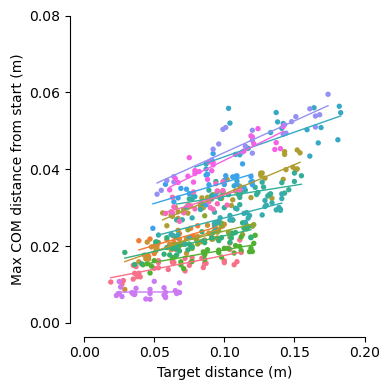

In [3]:
import ast
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import linregress

def reg(ax, x, y, c):
    if len(x) > 1:
        p = np.polyfit(x, y, 1)
        xx = np.linspace(x.min(), x.max(), 100)
        ax.plot(xx, np.polyval(p, xx), color=c, linewidth=1)

df = pd.read_csv("JumpKinematics.csv")
d = df[df["Experiment"] == "Distance"].copy()

def convert(x):
    try:
        return ast.literal_eval(x)
    except:
        return np.nan

data = []

for _, row in d.iterrows():
    x, y = convert(row["COM_x"]), convert(row["COM_y"])
    if not isinstance(x, list) or not isinstance(y, list):
        continue

    n = int(row["takeofftime(ms)"] * 2)
    x, y = np.array(x[:n+1]), np.array(y[:n+1])
    if len(x) > 1:
        dist = np.sqrt((x-x[0])**2 + (y-y[0])**2).max()
        data.append([row["TargetDistance"], dist * row["pixelsize(m)"], row["Individual ID"]])

plot_df = pd.DataFrame(data, columns=["TargetDistance", "MaxCOM", "Individual ID"])

# Regression statistics
stats_list = []
for ind, g in plot_df.groupby("Individual ID"):
    if len(g) > 1:
        r = linregress(g["TargetDistance"], g["MaxCOM"])
        stats_list.append([ind, len(g), r.slope, r.intercept, r.rvalue**2, r.pvalue, r.stderr])

stats_df = pd.DataFrame(
    stats_list,
    columns=["Individual ID", "N", "Slope", "Intercept", "R2", "p-value", "Std Err"]
).round(3)

stats_df["p-value"] = stats_df["p-value"].apply(
    lambda p: "<0.05" if pd.notna(p) and p < 0.05 else round(p, 3) if pd.notna(p) else np.nan
)
print(stats_df.to_string(index=False))

# Plot
fig, ax = plt.subplots(figsize=(4, 4))

inds = plot_df["Individual ID"].unique()
colors = sns.color_palette("husl", len(inds))
color_map = dict(zip(inds, colors))

sns.scatterplot(
    data=plot_df, x="TargetDistance", y="MaxCOM",
    hue="Individual ID", palette=color_map,
    s=15, edgecolors="none", legend=False, ax=ax
)

for ind, g in plot_df.groupby("Individual ID"):
    reg(ax, g["TargetDistance"].values, g["MaxCOM"].values, color_map[ind])

ax.set(
    xlabel="Target distance (m)",
    ylabel="Max COM distance from start (m)",
    xlim=(0, 0.2),
    ylim=(0, 0.08)
)

ax.xaxis.set_major_locator(ticker.MultipleLocator(0.05))
ax.yaxis.set_major_locator(ticker.MultipleLocator(0.02))

sns.despine(ax=ax, offset=10)

plt.tight_layout()
plt.savefig("Fig_DistanceTravelled.svg", format="svg", bbox_inches="tight")
plt.show()

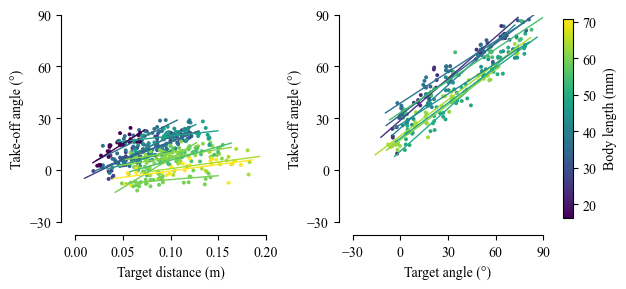

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.ticker import MultipleLocator

# Load dataset
df = pd.read_csv("JumpKinematics.csv").rename(columns={"bodylength(mm)": "BodyLength"})

# ----------------------------
# Helper: Regression line
# ----------------------------
def reg(ax, x, y, c):
    if len(x) > 1:
        p = np.polyfit(x, y, 1)
        xr = x.max() - x.min()
        xr = xr if xr > 0 else 1.0
        xx = np.linspace(x.min() - 0.1 * xr, x.max() + 0.1 * xr, 100)
        ax.plot(xx, np.polyval(p, xx), color=c, linewidth=1)


# ----------------------------
# Setup Figure
# ----------------------------
fig, axes = plt.subplots(1, 2, figsize=(6, 3))

ax_dist = axes[0]
ax_angle = axes[1]

# Shared Normalization & Colormap based on Body Length
norm = Normalize(vmin=df["BodyLength"].min(), vmax=df["BodyLength"].max())
cmap = plt.cm.viridis

# Map each Individual ID to a unique color determined by their BodyLength
ind_colors = (
    df.groupby("Individual ID")["BodyLength"]
    .first()
    .apply(lambda bl: cmap(norm(bl)))
    .to_dict()
)

# ----------------------------
# Plot 1: Distance vs TakeOffAngle
# ----------------------------
d_dist = df[df["Experiment"] == "Distance"]

# Scatter plot using individual-mapped body length colors
colors_dist = [ind_colors[i] for i in d_dist["Individual ID"]]
ax_dist.scatter(
    d_dist["TargetDistance"],
    d_dist["TakeOffAngle"],
    c=colors_dist,
    s=8,
    edgecolors="none",
)

# Individual Regression lines
for ind_id, group in d_dist.groupby("Individual ID"):
    reg(
        ax_dist,
        group["TargetDistance"],
        group["TakeOffAngle"],
        ind_colors[ind_id],
    )

ax_dist.set(
    xlim=(0, 0.2),
    ylim=(-30, 90),
    xlabel="Target distance (m)",
    ylabel="Take-off angle (°)",
)
ax_dist.xaxis.set_major_locator(MultipleLocator(0.05))
ax_dist.yaxis.set_major_locator(MultipleLocator(30))
sns.despine(ax=ax_dist, offset=10)

# ----------------------------
# Plot 2: Angle vs TakeOffAngle
# ----------------------------
d_angle = df[df["Experiment"] == "Angle"]

# Scatter plot
colors_angle = [ind_colors[i] for i in d_angle["Individual ID"]]
ax_angle.scatter(
    d_angle["TargetAngle"],
    d_angle["TakeOffAngle"],
    c=colors_angle,
    s=8,
    edgecolors="none",
)

# Individual Regression lines
for ind_id, group in d_angle.groupby("Individual ID"):
    reg(
        ax_angle,
        group["TargetAngle"],
        group["TakeOffAngle"],
        ind_colors[ind_id],
    )

ax_angle.set(
    xlim=(-30, 90),
    ylim=(-30, 90),
    xlabel="Target angle (°)",
    ylabel="Take-off angle (°)",
)
ax_angle.xaxis.set_major_locator(MultipleLocator(30))
ax_angle.yaxis.set_major_locator(MultipleLocator(30))
ax_angle.tick_params(labelleft=True)
sns.despine(ax=ax_angle, offset=10)

# ----------------------------
# Layout & Colorbar
# ----------------------------
plt.tight_layout()

# Colorbar for Body Length
sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, orientation="vertical", fraction=0.02, pad=0.04)
cbar.set_label("Body length (mm)")

# Save figures
#plt.savefig("FigS2ab.svg", format="svg", bbox_inches="tight")
#plt.savefig("FigS2ab.png", dpi=600, bbox_inches="tight")
plt.show()

# Statistics

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.formula.api as smf

# 1. Load data
df_jump = pd.read_csv("JumpKinematics.csv").rename(columns={"bodylength(mm)": "BodyLength"})
df_peer = pd.read_csv("PeeringKinematics.csv").rename(columns={"TargetDistance(mm)": "TargetDistance_Peer", "Frequency(Hz)": "Frequency", "Amplitude(mm)": "Amplitude"})
df_peer['peering_duration(ms)'] = pd.to_numeric(df_peer['peering_duration(ms)'], errors='coerce')
df_peer = df_peer[df_peer['type'] == 'Binocular']
df_peer = df_peer[df_peer['peering_duration(ms)'] > 1000]

df_dist = df_jump[df_jump["Experiment"] == "Distance"].copy()
df_angle = df_jump[df_jump["Experiment"] == "Angle"].copy()

tx, ty = (df_angle["Head_ax"] + df_angle["Head_bx"]) / 2, (df_angle["Head_ay"] + df_angle["Head_by"]) / 2
df_angle["HeadAngle"] = np.degrees(np.arctan2(df_angle["Head_bx"] - df_angle["Head_ax"], df_angle["Head_by"] - df_angle["Head_ay"]))
df_angle["TargetAngleFromHead"] = (np.degrees(np.arctan2(df_angle["TargetPlatform_x"] - tx, df_angle["TargetPlatform_y"] - ty)) - 90)

# Helper function to convert list string if needed
def get_angles(row, fs=2):
    data = eval(str(row["BodyAngle_TimeSeries"]))  # or json.loads / convert_to_list
    ti, td = int(row["takeofftime(ms)"] * fs), int(row["touchdown(ms)"] * fs)
    p100 = ti - int(100 * fs)
    
    if p100 >= 0 and td < len(data):
        return data[p100], data[ti], data[td]
    return np.nan, np.nan, np.nan

# Extract angles in one line
df_bodyangles = df_angle.dropna(subset=["touchdown(ms)"]).copy()
cols = ["BodyAngle_Pre100", "BodyAngle_Takeoff", "BodyAngle_Touchdown"]
df_bodyangles[cols] = df_bodyangles.apply(get_angles, axis=1, result_type="expand")

# 2. Define model specs with Figure labels
specs = [
    ("Fig. 2c", "TakeOffSpeed ~ TargetDistance", "~TargetDistance", df_dist),
    ("Fig. 2d", "TakeOffAngle ~ TargetDistance", "~TargetDistance", df_dist),
    ("Fig. 3c", "Frequency ~ TargetDistance_Peer", None, df_peer),
    ("Fig. 3d", "Amplitude ~ TargetDistance_Peer", None, df_peer),
    ("Fig. 4c", "TakeOffSpeed ~ TargetAngle", None, df_angle),
    ("Fig. 4d", "TakeOffAngle ~ TargetAngle", None, df_angle),
    ("Fig. 5a", "HeadAngle ~ TargetAngleFromHead", None, df_angle),
    ("Fig. 5c", "BodyAngle_Pre100 ~ TargetAngle", None, df_bodyangles),
    ("Fig. 5d", "BodyAngle_Takeoff ~ TargetAngle", None, df_bodyangles),
    ("Fig. 5e", "BodyAngle_Touchdown ~ TargetAngle", None, df_bodyangles)
]

# 3. Fit and summarize
fitted_models = {}
for i, (fig, formula, re, data) in enumerate(specs, 1):
    print(f"\n{'='*50}\n MODEL {i} [{fig}]: {formula}\n{'='*50}")
    kwargs = (
        {"re_formula": re}
        if re
        else {"vc_formula": None} if re is None else {}
    )

    res = smf.mixedlm(
        formula, data, groups=data["Individual ID"], **kwargs
    ).fit()
    fitted_models[i] = res
    print(res.summary())

# 4. Report results in a DataFrame
summary_rows = []
alpha_cutoff = 0.05
z_crit = stats.norm.ppf(1 - alpha_cutoff / 2)

for i, (fig, formula, re, data) in enumerate(specs, 1):
    res = fitted_models[i]
    
    # Metadata & Variances
    dep_var, n_obs, n_groups = res.model.endog_names, int(res.nobs), len(res.model.group_labels)
    cov = getattr(res, "cov_re", pd.DataFrame())
    
    group_var = cov.iloc[0, 0] if cov.shape[0] > 0 else np.nan
    has_slope = cov.shape[0] > 1 and cov.shape[1] > 1
    slope_var = cov.iloc[1, 1] if has_slope else np.nan
    slope_cov = cov.iloc[0, 1] if has_slope else np.nan

    # Level-2 Degrees of Freedom
    df_lvl2 = max(1, n_groups - 1)
    t_crit = stats.t.ppf(1 - alpha_cutoff / 2, df=df_lvl2)
    conf_int = res.conf_int()

    # Iterate Parameters
    for param in res.fe_params.index:
        coef = res.params[param]
        se = res.bse.get(param, np.nan)
        
        # Post-hoc Power Calculations
        ncp = abs(coef) / se if (se > 0 and pd.notna(se)) else 0
        pow_l1 = stats.norm.cdf(ncp - z_crit) + stats.norm.cdf(-ncp - z_crit)
        pow_l2 = stats.t.cdf(ncp - t_crit, df=df_lvl2) + stats.t.cdf(-ncp - t_crit, df=df_lvl2)

        summary_rows.append({
            "Figure": fig,
            "Model_ID": f"Model {i}",
            "Formula": formula,
            "Dependent_Variable": dep_var,
            "Predictor": param,
            "Coef": coef,
            "Std_Err": se,
            "z_value": res.tvalues.get(param, np.nan),
            "p-value": res.pvalues.get(param, np.nan),
            "CI_2.5%": conf_int.loc[param, 0] if param in conf_int.index else np.nan,
            "CI_97.5%": conf_int.loc[param, 1] if param in conf_int.index else np.nan,
            "Power_Lvl1": pow_l1,
            "Power_Lvl2": pow_l2,
            "Group_Var": group_var,
            "Random_Slope_Var": slope_var,
            "Group_x_Slope_Cov": slope_cov,
            "Residual_Var": res.scale,
            "Log_Likelihood": res.llf,
            "N_Obs": n_obs,
            "N_Groups": n_groups,
        })

# Create DataFrame and round all numeric columns at once
df_summary = pd.DataFrame(summary_rows).round(5)
df_summary["p-value"] = df_summary["p-value"].apply(
    lambda p: "<0.05" if pd.notna(p) and p < 0.05 else round(p, 3) if pd.notna(p) else np.nan
)

df_summary.to_csv("Statistics_MixedEffectsModel_Summary.csv", index=False)
print(df_summary.to_string())


 MODEL 1 [Fig. 2c]: TakeOffSpeed ~ TargetDistance
                Mixed Linear Model Regression Results
Model:                 MixedLM    Dependent Variable:    TakeOffSpeed
No. Observations:      440        Method:                REML        
No. Groups:            15         Scale:                 0.0025      
Min. group size:       20         Log-Likelihood:        640.9929    
Max. group size:       40         Converged:             Yes         
Mean group size:       29.3                                          
---------------------------------------------------------------------
                           Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------------
Intercept                   0.632    0.043 14.588 0.000  0.547  0.717
TargetDistance              4.012    0.301 13.315 0.000  3.421  4.602
Group Var                   0.027    0.218                           
Group x TargetDistance Cov -0.151    1.399             

c:\Users\Girish\miniconda3\envs\jump\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


            Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: BodyAngle_Pre100
No. Observations: 242     Method:             REML            
No. Groups:       10      Scale:              15.1393         
Min. group size:  20      Log-Likelihood:     -693.5130       
Max. group size:  26      Converged:          Yes             
Mean group size:  24.2                                        
---------------------------------------------------------------
                Coef.   Std.Err.    z     P>|z|  [0.025  0.975]
---------------------------------------------------------------
Intercept       37.158     1.924  19.316  0.000  33.388  40.928
TargetAngle      0.632     0.010  62.195  0.000   0.612   0.652
Group Var       35.214     4.426                               


 MODEL 9 [Fig. 5d]: BodyAngle_Takeoff ~ TargetAngle
             Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: BodyAngle_Takeoff
No. Observations: 2

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

# 1. Load data and clean column names (strip whitespace)
df_jump = pd.read_csv("JumpKinematics.csv")
df_jump.columns = df_jump.columns.str.strip()
df_jump = df_jump.rename(columns={"bodylength(mm)": "BodyLength"})

df_peer = pd.read_csv("PeeringKinematics.csv")
df_peer.columns = df_peer.columns.str.strip()
df_peer = df_peer.rename(columns={
    "TargetDistance(mm)": "TargetDistance_Peer", 
    "Frequency(Hz)": "Frequency", 
    "Amplitude(mm)": "Amplitude",
    "bodylength(mm)": "BodyLength",
    "mass(g)": "BodyMass"
})

# Ensure BodyMass is numeric (handles any string formatting or whitespace issues)
if "BodyMass" in df_peer.columns:
    df_peer["BodyMass"] = pd.to_numeric(df_peer["BodyMass"], errors='coerce')

df_peer['peering_duration(ms)'] = pd.to_numeric(df_peer['peering_duration(ms)'], errors='coerce')
df_peer = df_peer[df_peer['type'] == 'Binocular']
df_peer = df_peer[df_peer['peering_duration(ms)'] > 1000]

# Fallback: If BodyMass is still all NaN in df_peer, map it from df_jump using Individual ID
if "BodyMass" not in df_peer.columns or df_peer["BodyMass"].isna().all():
    for mass_col in ["mass(g)", "Mass(g)", "body_mass(g)", "BodyMass(g)"]:
        if mass_col in df_jump.columns:
            ind_mass_map = df_jump.groupby("Individual ID")[mass_col].first().to_dict()
            df_peer["BodyMass"] = df_peer["Individual ID"].map(ind_mass_map)
            break

df_dist = df_jump[df_jump["Experiment"] == "Distance"].copy()
df_angle = df_jump[df_jump["Experiment"] == "Angle"].copy()

tx, ty = (df_angle["Head_ax"] + df_angle["Head_bx"]) / 2, (df_angle["Head_ay"] + df_angle["Head_by"]) / 2
df_angle["HeadAngle"] = np.degrees(np.arctan2(df_angle["Head_bx"] - df_angle["Head_ax"], df_angle["Head_by"] - df_angle["Head_ay"]))
df_angle["TargetAngleFromHead"] = (np.degrees(np.arctan2(df_angle["TargetPlatform_x"] - tx, df_angle["TargetPlatform_y"] - ty)) - 90)

# Helper function to convert list string if needed
def get_angles(row, fs=2):
    data = eval(str(row["BodyAngle_TimeSeries"]))  # or json.loads / convert_to_list
    ti, td = int(row["takeofftime(ms)"] * fs), int(row["touchdown(ms)"] * fs)
    p100 = ti - int(100 * fs)
    
    if p100 >= 0 and td < len(data):
        return data[p100], data[ti], data[td]
    return np.nan, np.nan, np.nan

# Extract angles in one line
df_bodyangles = df_angle.dropna(subset=["touchdown(ms)"]).copy()
cols = ["BodyAngle_Pre100", "BodyAngle_Takeoff", "BodyAngle_Touchdown"]
df_bodyangles[cols] = df_bodyangles.apply(get_angles, axis=1, result_type="expand")

# 1. Define your regression specifications including Figure labels
regression_specs = [
    ("Fig. 2c", "Distance", "TakeOffSpeed", "TargetDistance"),
    ("Fig. 2d", "Distance", "TakeOffAngle", "TargetDistance"),
    ("Fig. 3c", "Peering", "Frequency", "TargetDistance_Peer"),
    ("Fig. 3d", "Peering", "Amplitude", "TargetDistance_Peer"),
    ("Fig. 4c", "Angle", "TakeOffSpeed", "TargetAngle"),
    ("Fig. 4d", "Angle", "TakeOffAngle", "TargetAngle"),
    ("Fig. 5a", "Angle", "HeadAngle", "TargetAngleFromHead"),
    ("Fig. 5c", "Angle", "BodyAngle_Pre100", "TargetAngle"),
    ("Fig. 5d", "Angle", "BodyAngle_Takeoff", "TargetAngle"),
    ("Fig. 5e", "Angle", "BodyAngle_Touchdown", "TargetAngle")
]

def run_individual_regressions_extended(specs, df_dist, df_peer, df_angle, df_bodyangles):
    """
    Runs individual-level linear regressions across specified models, 
    including Figure tags, correct dataframe selection, and mass column mapping.
    """
    results_list = []
    
    for fig_label, experiment_name, y_var, x_var in specs:
        # Select the correct base dataframe depending on the variable requirements
        if y_var.startswith("BodyAngle_"):
            data = df_bodyangles
        elif experiment_name == "Distance":
            data = df_dist
        elif experiment_name == "Peering":
            data = df_peer
        else:
            data = df_angle
            
        # Filter by experiment if applicable and present in columns
        if "Experiment" in data.columns and experiment_name in data["Experiment"].values:
            subset = data[data["Experiment"] == experiment_name].copy()
        else:
            subset = data.copy()
            
        # Check if required columns exist
        if y_var not in subset.columns or x_var not in subset.columns:
            print(f"Skipping [{fig_label} | {experiment_name}: {y_var} ~ {x_var}] — columns missing in DataFrame.")
            continue
            
        # Group by Individual ID
        grouped = subset.groupby("Individual ID")
        
        for ind_id, group in grouped:
            # Drop rows with missing values in x or y
            clean_group = group.dropna(subset=[y_var, x_var])
            
            # Require at least a minimum sample size to fit a regression (e.g., n >= 3)
            if len(clean_group) < 3:
                continue
                
            y = clean_group[y_var]
            X = sm.add_constant(clean_group[x_var]) # Adds intercept
            
            # Extract individual metadata, checking for alternative body length naming
            body_length = np.nan
            for bl_col in ["BodyLength", "bodylength(mm)", "body_length", "BodyLength(mm)"]:
                if bl_col in clean_group.columns and not clean_group[bl_col].isna().all():
                    body_length = clean_group[bl_col].iloc[0]
                    break
            
            # Extract individual metadata, checking for mass naming
            body_mass = np.nan
            for mass_col in ["BodyMass", "mass(g)", "Mass(g)", "body_mass(g)", "BodyMass(g)"]:
                if mass_col in clean_group.columns and not clean_group[mass_col].isna().all():
                    body_mass = clean_group[mass_col].iloc[0]
                    break
            
            try:
                # Fit OLS model
                model = sm.OLS(y, X).fit()
                
                results_list.append({
                    "Figure": fig_label,
                    "Experiment": experiment_name,
                    "Dependent_Variable": y_var,
                    "Independent_Variable": x_var,
                    "Individual ID": ind_id,
                    "Body Length (mm)": (body_length * 4).round() / 4,
                    "Body Mass (g)": body_mass,
                    "Sample size": int(model.nobs),
                    "Slope": model.params[x_var],
                    "Intercept": model.params["const"],
                    "R-square": model.rsquared,
                    "p-value": model.pvalues[x_var],
                    "Standard error": model.bse[x_var]
                })
            except Exception as e:
                print(f"Could not fit model for Individual {ind_id} ({y_var} ~ {x_var}): {e}")
                
    return pd.DataFrame(results_list)

# 2. Execute the function using your dataframes
df_individual_summary = run_individual_regressions_extended(
    regression_specs, df_dist, df_peer, df_angle, df_bodyangles
)

# 3. Post-process numeric columns (rounded to 3 decimals) and format p-values (< 0.05)
numeric_cols = ["Body Length (mm)", "Body Mass (g)", "Sample size", "Slope", "Intercept", "R-square", "Standard error"]
df_individual_summary[numeric_cols] = df_individual_summary[numeric_cols]

df_individual_summary["p-value"] = df_individual_summary["p-value"].apply(
    lambda p: "<0.05" if pd.notna(p) and p < 0.05 else round(p, 3) if pd.notna(p) else np.nan
)

print(df_individual_summary.to_string())

# Save the combined DataFrame to CSV
df_individual_summary.to_csv("Statistics_IndividualLevelRegressions_Summary.csv", index=False)

      Figure Experiment   Dependent_Variable Independent_Variable Individual ID  Body Length (mm)  Body Mass (g)  Sample size       Slope  Intercept  R-square p-value  Standard error
0    Fig. 2c   Distance         TakeOffSpeed       TargetDistance           M12             27.25         0.1287           40    3.478108   0.626836  0.813921   <0.05        0.269779
1    Fig. 2c   Distance         TakeOffSpeed       TargetDistance           M13             43.75         0.6250           20    5.201401   0.504511  0.859155   <0.05        0.496385
2    Fig. 2c   Distance         TakeOffSpeed       TargetDistance           M14             36.75         0.4060           31    5.542822   0.501211  0.848675   <0.05        0.434628
3    Fig. 2c   Distance         TakeOffSpeed       TargetDistance           M15             61.50         1.7113           40    4.781067   0.499137  0.888304   <0.05        0.275024
4    Fig. 2c   Distance         TakeOffSpeed       TargetDistance           M16      